# **RAFT — Motion Descriptor, Batch Processing**

Pure RAFT descriptor-extraction pipeline. RAFT is used strictly as a
frozen, independent optical-flow estimator for motion characterization --
no VFI model inference, no motion-category classification happen here.

Pipeline: shared test split -> RAFT forward/backward flow -> four motion
descriptors (+ diagnostics) -> batch processing -> checkpointed CSV.

### Load shared test split (already established -- not re-derived)

## Notebook reading guide: final 170-clip calibration pipeline

This notebook retains earlier descriptor checks, threshold sweeps, visual-inspection helpers, and classifier experiments as an audit trail. They are **exploratory or historical** and are not the authoritative source of the final motion labels or reported CSVs.

For the final pipeline, read the cells in this order:

1. Extract RAFT descriptors for the fixed splits.
2. Run the **final 170-clip calibration search** (the self-contained automatic descriptor/classifier search).
3. Run **Final Classifier**, then classify the training split and untouched test split.
4. Use the final diagnostic-score cells to select the weak category.

The 170 calibration clips are separate from the 3,601-clip test set. The displayed outputs are preserved as execution evidence; historical cells are retained for transparency and should not be interpreted as an alternative final labelling procedure.


In [3]:
import os
import pandas as pd

SPLIT_ROOT = "/kaggle/input/datasets/hibro00/vimeo-triplet-split"

print("Split dataset contents:")
print(os.listdir(SPLIT_ROOT))

# Find the CSV automatically
csv_files = [
    f for f in os.listdir(SPLIT_ROOT)
    if f.lower().endswith(".csv")
]

print("\nCSV files:", csv_files)

assert len(csv_files) >= 1, "No CSV found in split dataset."

SPLITS_PATH = os.path.join(SPLIT_ROOT, csv_files[0])
splits = pd.read_csv(SPLITS_PATH)

print("\nUsing:", SPLITS_PATH)
print("Shape:", splits.shape)
print("\nColumns:", list(splits.columns))
print("\nSplit counts:")
print(splits["split"].value_counts())

print("\nFirst rows:")
display(splits.head())

Split dataset contents:
['splits.csv']

CSV files: ['splits.csv']

Using: /kaggle/input/datasets/hibro00/vimeo-triplet-split/splits.csv
Shape: (55095, 2)

Columns: ['clip_id', 'split']

Split counts:
split
train          51324
test            3601
calibration      170
Name: count, dtype: int64

First rows:


,clip_id,split
0,00001/0001,train
1,00001/0002,train
2,00001/0003,train
3,00001/0004,train
4,00001/0005,train


In [4]:
# Validate the expected split structure

calib = splits[splits["split"] == "calibration"]
test = splits[splits["split"] == "test"]

print("Calibration:", len(calib))
print("Test:", len(test))

overlap = set(calib["clip_id"]) & set(test["clip_id"])

print("Calibration/Test overlap:", len(overlap))

assert len(calib) == 170, f"Expected 50 calibration clips, got {len(calib)}"
assert len(test) == 3601, f"Expected 3732 test clips, got {len(test)}"
assert len(overlap) == 0, "Calibration/test leakage detected!"

print("\nSPLIT VALIDATION PASSED")

Calibration: 170
Test: 3601
Calibration/Test overlap: 0

SPLIT VALIDATION PASSED


# ***RAFT***

In [5]:
import sys
import os
import torch

RAFT_ROOT = "/kaggle/input/datasets/hibro00/raft-kaggle"
CORE_PATH = RAFT_ROOT + "/core"

for p in (RAFT_ROOT, CORE_PATH):
    if p not in sys.path:
        sys.path.insert(0, p)

import argparse
from raft import RAFT
from utils.utils import InputPadder

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

args = argparse.Namespace(small=False, mixed_precision=False, alternate_corr=False)

raft_model = torch.nn.DataParallel(RAFT(args))
checkpoint = torch.load(f"{RAFT_ROOT}/models/raft-things.pth", map_location=DEVICE)
raft_model.load_state_dict(checkpoint)
raft_model = raft_model.module.to(DEVICE).eval()

print("RAFT model loaded.")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())


RAFT model loaded.
PyTorch: 2.10.0+cu128
CUDA: True


In [6]:
import torch.nn.functional as F
from typing import Optional, Tuple, Dict

KERNEL_SIZE = 7
MAGNITUDE_THRESHOLD = 0.5
MAG_EPSILON = 0.5
ALPHA = 0.05
BETA = 0.5


def compute_local_mean(x, kernel_size=7):
    assert kernel_size % 2 == 1, "kernel_size must be odd"
    pad = kernel_size // 2
    channels = x.shape[1]
    kernel = torch.ones(channels, 1, kernel_size, kernel_size, device=x.device, dtype=x.dtype)
    kernel /= kernel_size * kernel_size
    x_padded = F.pad(x, (pad, pad, pad, pad), mode="replicate")
    return F.conv2d(x_padded, kernel, groups=channels)


def compute_local_variance(x, kernel_size=7):
    mean_x = compute_local_mean(x, kernel_size)
    mean_x2 = compute_local_mean(x ** 2, kernel_size)
    return (mean_x2 - mean_x ** 2).clamp(min=0.0)


def compute_spatial_gradients_sobel(x):
    kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]],
                       device=x.device, dtype=x.dtype).view(1, 1, 3, 3) / 8.0
    ky = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]],
                       device=x.device, dtype=x.dtype).view(1, 1, 3, 3) / 8.0
    x_padded = F.pad(x, (1, 1, 1, 1), mode="replicate")
    return F.conv2d(x_padded, kx), F.conv2d(x_padded, ky)


def warp_flow(flow_to_warp, flow_guide):
    B, _, H, W = flow_guide.shape
    device = flow_guide.device
    dtype = flow_guide.dtype

    yy, xx = torch.meshgrid(
        torch.arange(H, device=device, dtype=dtype),
        torch.arange(W, device=device, dtype=dtype),
        indexing="ij"
    )
    grid = torch.stack([xx, yy], dim=0).unsqueeze(0).expand(B, -1, -1, -1)

    sample_coords = grid + flow_guide
    x_norm = 2.0 * sample_coords[:, 0] / max(W - 1, 1) - 1.0
    y_norm = 2.0 * sample_coords[:, 1] / max(H - 1, 1) - 1.0
    grid_norm = torch.stack([x_norm, y_norm], dim=-1)

    warped = F.grid_sample(flow_to_warp, grid_norm, mode="bilinear",
                            padding_mode="zeros", align_corners=True)

    valid = ((x_norm >= -1) & (x_norm <= 1) & (y_norm >= -1) & (y_norm <= 1)).unsqueeze(1)
    return warped, valid


def compute_motion_magnitude(flow_fwd, mask=None, magnitude_threshold=0.5, eps=1e-8):
    u = flow_fwd[:, 0:1]
    v = flow_fwd[:, 1:2]
    magnitude = torch.sqrt(u ** 2 + v ** 2 + eps)

    active = magnitude > magnitude_threshold
    if mask is not None:
        active = active & (mask > 0.5)

    means, p90s, ratios = [], [], []
    for i in range(flow_fwd.shape[0]):
        mag_i = magnitude[i, 0]
        active_i = active[i, 0]
        num_active = active_i.sum()
        total = mag_i.numel()
        ratios.append(num_active.float() / total)
        if num_active > 0:
            values = mag_i[active_i]
            means.append(values.mean())
            p90s.append(torch.quantile(values, 0.90))
        else:
            means.append(mag_i.mean())
            p90s.append(torch.quantile(mag_i.reshape(-1), 0.90))

    return torch.stack(means), torch.stack(p90s), torch.stack(ratios)


def compute_angular_variance(flow_fwd, kernel_size=7, mag_epsilon=0.5, mask=None):
    """Static pixels excluded BEFORE local circular statistics (fixed version)."""
    u = flow_fwd[:, 0:1]
    v = flow_fwd[:, 1:2]
    magnitude = torch.sqrt(u ** 2 + v ** 2 + 1e-8)

    valid = (magnitude > mag_epsilon).to(flow_fwd.dtype)
    if mask is not None:
        valid *= (mask > 0.5).to(flow_fwd.dtype)

    cos_theta = (u / magnitude) * valid
    sin_theta = (v / magnitude) * valid

    local_cos_sum = compute_local_mean(cos_theta, kernel_size)
    local_sin_sum = compute_local_mean(sin_theta, kernel_size)
    local_valid = compute_local_mean(valid, kernel_size).clamp(min=1e-6)

    mean_cos = local_cos_sum / local_valid
    mean_sin = local_sin_sum / local_valid
    R = torch.sqrt(mean_cos ** 2 + mean_sin ** 2 + 1e-8).clamp(max=1.0)
    circular_variance = 1.0 - R

    denominator = valid.sum(dim=[1, 2, 3]).clamp(min=1.0)
    return (circular_variance * valid).sum(dim=[1, 2, 3]) / denominator


def compute_occlusion_ratio(flow_fwd, flow_bwd, alpha=0.05, beta=0.5):
    warped_bwd, valid_mask = warp_flow(flow_to_warp=flow_bwd, flow_guide=flow_fwd)
    error = torch.norm(flow_fwd + warped_bwd, dim=1, keepdim=True)
    mag_fwd = torch.norm(flow_fwd, dim=1, keepdim=True)
    mag_bwd = torch.norm(warped_bwd, dim=1, keepdim=True)
    threshold = alpha * (mag_fwd + mag_bwd) + beta
    inconsistent = error > threshold

    valid = valid_mask.to(dtype=flow_fwd.dtype)
    inconsistent_valid = (inconsistent & valid_mask).to(flow_fwd.dtype)
    denominator = valid.sum(dim=[1, 2, 3]).clamp(min=1.0)
    return inconsistent_valid.sum(dim=[1, 2, 3]) / denominator


def compute_occlusion_diagnostics(flow_fwd, flow_bwd, eps=1e-6):
    """Auxiliary only -- not used for classification."""
    warped_bwd, valid_mask = warp_flow(flow_to_warp=flow_bwd, flow_guide=flow_fwd)
    error = torch.norm(flow_fwd + warped_bwd, dim=1, keepdim=True)
    mag_fwd = torch.norm(flow_fwd, dim=1, keepdim=True)
    mag_bwd = torch.norm(warped_bwd, dim=1, keepdim=True)
    relative_error = error / (mag_fwd + mag_bwd + eps)

    valid = valid_mask.to(dtype=flow_fwd.dtype)
    denominator = valid.sum(dim=[1, 2, 3]).clamp(min=1.0)
    mean_fb_error = (error * valid).sum(dim=[1, 2, 3]) / denominator
    mean_relative_fb_error = (relative_error * valid).sum(dim=[1, 2, 3]) / denominator
    return mean_fb_error, mean_relative_fb_error


def compute_non_rigidity_score(flow_fwd, kernel_size=7, mask=None,
                                suppress_boundaries=False, boundary_threshold=2.0):
    """Proposal-faithful: divergence + shear, spatial variance."""
    u = flow_fwd[:, 0:1]
    v = flow_fwd[:, 1:2]
    du_dx, du_dy = compute_spatial_gradients_sobel(u)
    dv_dx, dv_dy = compute_spatial_gradients_sobel(v)

    divergence = du_dx + dv_dy
    shear = du_dy + dv_dx

    variance_div = compute_local_variance(divergence, kernel_size)
    variance_shear = compute_local_variance(shear, kernel_size)
    non_rigid_map = variance_div + variance_shear

    eval_mask = torch.ones_like(non_rigid_map)
    if mask is not None:
        eval_mask *= (mask > 0.5).to(flow_fwd.dtype)

    if suppress_boundaries:
        magnitude = torch.sqrt(u ** 2 + v ** 2 + 1e-8)
        dmag_dx, dmag_dy = compute_spatial_gradients_sobel(magnitude)
        magnitude_gradient = torch.sqrt(dmag_dx ** 2 + dmag_dy ** 2 + 1e-8)
        smooth_region = (magnitude_gradient < boundary_threshold).to(flow_fwd.dtype)
        eval_mask *= smooth_region

    denominator = eval_mask.sum(dim=[1, 2, 3]).clamp(min=1.0)
    return (non_rigid_map * eval_mask).sum(dim=[1, 2, 3]) / denominator


def compute_non_rigidity_score_improved(flow_fwd, kernel_size=7, mask=None):
    """Experimental: full local-Jacobian-inconsistency (Frobenius norm)."""
    u = flow_fwd[:, 0:1]
    v = flow_fwd[:, 1:2]
    du_dx, du_dy = compute_spatial_gradients_sobel(u)
    dv_dx, dv_dy = compute_spatial_gradients_sobel(v)

    du_dx_mean = compute_local_mean(du_dx, kernel_size)
    du_dy_mean = compute_local_mean(du_dy, kernel_size)
    dv_dx_mean = compute_local_mean(dv_dx, kernel_size)
    dv_dy_mean = compute_local_mean(dv_dy, kernel_size)

    diff_sq = ((du_dx - du_dx_mean) ** 2 + (du_dy - du_dy_mean) ** 2 +
               (dv_dx - dv_dx_mean) ** 2 + (dv_dy - dv_dy_mean) ** 2)
    frob_norm = torch.sqrt(diff_sq + 1e-8)

    eval_mask = torch.ones_like(frob_norm)
    if mask is not None:
        eval_mask *= (mask > 0.5).to(flow_fwd.dtype)

    denominator = eval_mask.sum(dim=[1, 2, 3]).clamp(min=1.0)
    return (frob_norm * eval_mask).sum(dim=[1, 2, 3]) / denominator


def compute_descriptors(flow_fwd, flow_bwd, mask=None, kernel_size=7,
                         magnitude_threshold=0.5, mag_epsilon=0.5,
                         alpha=0.05, beta=0.5, suppress_boundaries=False):
    """
    Four-descriptor pipeline (magnitude / angular variance / occlusion ratio /
    non-rigidity). Both non-rigidity variants are ALWAYS computed and returned
    as separate raw scalars -- no classification-facing "non_rigidity" value
    is produced here; choosing between variants happens later, at calibration.
    """
    single = False
    if flow_fwd.ndim == 3:
        flow_fwd = flow_fwd.unsqueeze(0)
        flow_bwd = flow_bwd.unsqueeze(0)
        single = True

    if mask is not None:
        if mask.ndim == 2:
            mask = mask.unsqueeze(0).unsqueeze(0)
        elif mask.ndim == 3:
            mask = mask.unsqueeze(1)

    m, p90, active_ratio = compute_motion_magnitude(flow_fwd, mask=mask, magnitude_threshold=magnitude_threshold)
    a = compute_angular_variance(flow_fwd, kernel_size=kernel_size, mag_epsilon=mag_epsilon, mask=mask)
    o = compute_occlusion_ratio(flow_fwd, flow_bwd, alpha=alpha, beta=beta)
    mean_fb_error, mean_relative_fb_error = compute_occlusion_diagnostics(flow_fwd, flow_bwd)
    n_original = compute_non_rigidity_score(flow_fwd, kernel_size=kernel_size, mask=mask, suppress_boundaries=suppress_boundaries)
    n_improved = compute_non_rigidity_score_improved(flow_fwd, kernel_size=kernel_size, mask=mask)

    if single:
        return {
            "primary": {
                "magnitude": m.item(), "angular_variance": a.item(),
                "occlusion_ratio": o.item()
            },
            "secondary": {
                "p90_magnitude": p90.item(), "active_pixel_ratio": active_ratio.item(),
                "mean_fb_error": mean_fb_error.item(), "mean_relative_fb_error": mean_relative_fb_error.item(),
                "non_rigidity_original": n_original.item(), "non_rigidity_improved": n_improved.item()
            }
        }

    return {
        "primary": {"magnitude": m, "angular_variance": a, "occlusion_ratio": o},
        "secondary": {
            "p90_magnitude": p90, "active_pixel_ratio": active_ratio,
            "mean_fb_error": mean_fb_error, "mean_relative_fb_error": mean_relative_fb_error,
            "non_rigidity_original": n_original, "non_rigidity_improved": n_improved
        }
    }


print("RAFT descriptor pipeline ready (both non-rigidity variants always computed, no classification here).")


RAFT descriptor pipeline ready (both non-rigidity variants always computed, no classification here).


In [7]:
# ============================================================
# 170-CLIP CALIBRATION DESCRIPTOR EXTRACTION
# ============================================================

import warnings

warnings.filterwarnings(
    "ignore",
    message=r"`torch\.cuda\.amp\.autocast.*is deprecated.*",
    category=FutureWarning
)

import os
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image

VIMEO_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet"
CALIB_OUTPUT_PATH = "/kaggle/working/vimeo_170_motion_descriptors.csv"

# Use the exact 170 clips defined by the shared calibration split
calib_ids = calib["clip_id"].tolist()

assert len(calib_ids) == 170, f"Expected 170 calibration clips, got {len(calib_ids)}"
assert len(set(calib_ids)) == 170, "Duplicate calibration clip IDs detected"

calib_results = []
run_start = time.time()

print(f"Starting RAFT descriptor extraction for {len(calib_ids)} calibration clips...\n")

for idx, clip_id in enumerate(calib_ids, start=1):

    clip_start = time.time()

    try:
        clip_dir = os.path.join(VIMEO_ROOT, "sequences", clip_id)

        # Load endpoint frames exactly like the main batch pipeline
        im1 = np.array(
            Image.open(f"{clip_dir}/im1.png").convert("RGB")
        )
        im3 = np.array(
            Image.open(f"{clip_dir}/im3.png").convert("RGB")
        )

        im1 = torch.from_numpy(im1).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE)
        im3 = torch.from_numpy(im3).permute(2, 0, 1).float().unsqueeze(0).to(DEVICE)

        # SAME padding/inference procedure as the main pipeline
        padder = InputPadder(im1.shape, mode="sintel")
        im1_p, im3_p = padder.pad(im1, im3)

        with torch.no_grad():
            _, flow_fwd = raft_model(
                im1_p, im3_p,
                iters=20,
                test_mode=True
            )

            _, flow_bwd = raft_model(
                im3_p, im1_p,
                iters=20,
                test_mode=True
            )

        # Remove padding before descriptor calculation
        flow_fwd = padder.unpad(flow_fwd)
        flow_bwd = padder.unpad(flow_bwd)

        desc = compute_descriptors(
            flow_fwd,
            flow_bwd,
            kernel_size=KERNEL_SIZE,
            magnitude_threshold=MAGNITUDE_THRESHOLD,
            mag_epsilon=MAG_EPSILON,
            alpha=ALPHA,
            beta=BETA,
            suppress_boundaries=False
        )

        row = {
            "clip_id": clip_id,
            "magnitude": desc["primary"]["magnitude"].item(),
            "p90_magnitude": desc["secondary"]["p90_magnitude"].item(),
            "active_pixel_ratio": desc["secondary"]["active_pixel_ratio"].item(),
            "angular_variance": desc["primary"]["angular_variance"].item(),
            "occlusion_ratio": desc["primary"]["occlusion_ratio"].item(),
            "mean_fb_error": desc["secondary"]["mean_fb_error"].item(),
            "mean_relative_fb_error": desc["secondary"]["mean_relative_fb_error"].item(),
            "non_rigidity_original": desc["secondary"]["non_rigidity_original"].item(),
            "non_rigidity_improved": desc["secondary"]["non_rigidity_improved"].item(),
            "status": "success",
            "time_sec": time.time() - clip_start
        }

        calib_results.append(row)

        print(
            f"[{idx:03d}/170] {clip_id} | "
            f"m={row['magnitude']:.3f} | "
            f"a={row['angular_variance']:.4f} | "
            f"o={row['occlusion_ratio']:.3f} | "
            f"n_orig={row['non_rigidity_original']:.4f} | "
            f"n_imp={row['non_rigidity_improved']:.4f} | "
            f"{row['time_sec']:.1f}s"
        )

        del im1, im3, im1_p, im3_p
        del flow_fwd, flow_bwd, desc
        torch.cuda.empty_cache()

    except Exception as e:

        elapsed = time.time() - clip_start

        print(f"[{idx:03d}/170] FAILED: {clip_id}")
        print("Error:", repr(e))

        calib_results.append({
            "clip_id": clip_id,
            "magnitude": np.nan,
            "p90_magnitude": np.nan,
            "active_pixel_ratio": np.nan,
            "angular_variance": np.nan,
            "occlusion_ratio": np.nan,
            "mean_fb_error": np.nan,
            "mean_relative_fb_error": np.nan,
            "non_rigidity_original": np.nan,
            "non_rigidity_improved": np.nan,
            "status": "failed",
            "time_sec": elapsed
        })

    # Save after every clip
    calib_df = pd.DataFrame(calib_results)

    calib_df = calib_df[
        [
            "clip_id",
            "magnitude",
            "p90_magnitude",
            "active_pixel_ratio",
            "angular_variance",
            "occlusion_ratio",
            "mean_fb_error",
            "mean_relative_fb_error",
            "non_rigidity_original",
            "non_rigidity_improved",
            "status",
            "time_sec"
        ]
    ]

    calib_df.to_csv(CALIB_OUTPUT_PATH, index=False)


# ============================================================
# FINAL VERIFICATION
# ============================================================

expected_columns = [
    "clip_id",
    "magnitude",
    "p90_magnitude",
    "active_pixel_ratio",
    "angular_variance",
    "occlusion_ratio",
    "mean_fb_error",
    "mean_relative_fb_error",
    "non_rigidity_original",
    "non_rigidity_improved",
    "status",
    "time_sec"
]

assert list(calib_df.columns) == expected_columns
assert len(calib_df) == 170
assert calib_df["clip_id"].nunique() == 170

print("\n========================================")
print("170-CLIP CALIBRATION COMPLETE")
print("========================================")
print(f"Successful: {(calib_df['status'] == 'success').sum()}")
print(f"Failed:     {(calib_df['status'] == 'failed').sum()}")
print(f"Total time: {(time.time() - run_start)/60:.2f} minutes")
print(f"Saved to:   {CALIB_OUTPUT_PATH}")
print("Column schema verified.")

Starting RAFT descriptor extraction for 170 calibration clips...



/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[001/170] 00001/0622 | m=7.400 | a=0.0001 | o=0.008 | n_orig=0.0056 | n_imp=0.0155 | 2.3s
[002/170] 00006/0166 | m=10.337 | a=0.0213 | o=0.093 | n_orig=0.2673 | n_imp=0.1099 | 0.2s
[003/170] 00010/0663 | m=4.164 | a=0.0017 | o=0.170 | n_orig=0.0320 | n_imp=0.0451 | 0.2s
[004/170] 00014/0007 | m=7.329 | a=0.0042 | o=0.065 | n_orig=0.1478 | n_imp=0.0765 | 0.2s
[005/170] 00017/0583 | m=7.828 | a=0.0007 | o=0.064 | n_orig=0.0266 | n_imp=0.0390 | 0.2s
[006/170] 00017/0663 | m=4.699 | a=0.0004 | o=0.068 | n_orig=0.1015 | n_imp=0.0546 | 0.2s
[007/170] 00019/0445 | m=5.389 | a=0.0067 | o=0.046 | n_orig=0.0299 | n_imp=0.0485 | 0.2s
[008/170] 00019/0751 | m=23.266 | a=0.0016 | o=0.022 | n_orig=0.1711 | n_imp=0.0415 | 0.2s
[009/170] 00020/0420 | m=4.239 | a=0.0055 | o=0.073 | n_orig=0.8600 | n_imp=0.1376 | 0.2s
[010/170] 00022/0826 | m=7.107 | a=0.0101 | o=0.074 | n_orig=0.0463 | n_imp=0.0315 | 0.2s
[011/170] 00024/0904 | m=9.442 | a=0.0004 | o=0.016 | n_orig=0.0188 | n_imp=0.0225 | 0.2s
[012/170

In [15]:
# ============================================================
# 170-CLIP CALIBRATION INSPECTION
# ============================================================

import pandas as pd
import numpy as np

CSV_PATH = "/kaggle/working/vimeo_170_motion_descriptors.csv"

df = pd.read_csv(CSV_PATH)

# ------------------------------------------------------------
# Basic summary
# ------------------------------------------------------------

print("=" * 70)
print("170-CLIP CALIBRATION SUMMARY")
print("=" * 70)

print(f"Total clips     : {len(df)}")
print(f"Successful      : {(df['status'] == 'success').sum()}")
print(f"Failed          : {(df['status'] == 'failed').sum()}")

# ------------------------------------------------------------
# Descriptor columns
# ------------------------------------------------------------

descriptors = [
    "magnitude",
    "angular_variance",
    "occlusion_ratio",
    "non_rigidity_original",
    "non_rigidity_improved"
]

print("\n" + "=" * 70)
print("DESCRIPTOR STATISTICS")
print("=" * 70)

stats = df[descriptors].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
).T

print(
    stats[
        ["mean", "std", "min", "10%", "25%", "50%",
         "75%", "90%", "95%", "max"]
    ].round(5)
)

# ------------------------------------------------------------
# Standardized descriptors
# ------------------------------------------------------------

z_df = df.copy()

for col in descriptors:
    mean = z_df[col].mean()
    std = z_df[col].std()

    z_df[col + "_z"] = (
        (z_df[col] - mean) / std
        if std > 0 else 0
    )

# ------------------------------------------------------------
# Top clips for each descriptor
# ------------------------------------------------------------

def show_top(df, metric, n=5):

    print("\n" + "=" * 70)
    print(f"TOP {n} BY {metric.upper()}")
    print("=" * 70)

    cols = [
        "clip_id",
        metric,
        "magnitude",
        "angular_variance",
        "occlusion_ratio",
        "non_rigidity_original",
        "non_rigidity_improved"
    ]

    top = (
        df.nlargest(n, metric)[cols]
        .reset_index(drop=True)
    )

    print(top.round(5).to_string(index=False))

    return top


top_magnitude = show_top(df, "magnitude")
top_angular = show_top(df, "angular_variance")
top_occlusion = show_top(df, "occlusion_ratio")
top_nonrigid_original = show_top(df, "non_rigidity_original")
top_nonrigid_improved = show_top(df, "non_rigidity_improved")

# ------------------------------------------------------------
# Compare the two non-rigidity formulations
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NON-RIGIDITY COMPARISON")
print("=" * 70)

nr_compare = df[
    [
        "clip_id",
        "non_rigidity_original",
        "non_rigidity_improved"
    ]
].copy()

nr_compare["difference"] = (
    nr_compare["non_rigidity_improved"]
    - nr_compare["non_rigidity_original"]
)

print(
    nr_compare
    .sort_values("difference", ascending=False)
    .head(10)
    .round(5)
    .to_string(index=False)
)

# ------------------------------------------------------------
# Correlation between descriptors
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DESCRIPTOR CORRELATION")
print("=" * 70)

print(
    df[descriptors]
    .corr()
    .round(3)
)

# ------------------------------------------------------------
# Save standardized calibration data
# ------------------------------------------------------------

z_columns = [
    "clip_id"
] + [
    col + "_z" for col in descriptors
]

z_output = "/kaggle/working/vimeo_170_motion_descriptors_standardized.csv"

z_df[z_columns].to_csv(z_output, index=False)

print("\n" + "=" * 70)
print("INSPECTION COMPLETE")
print("=" * 70)
print(f"Standardized CSV saved to:")
print(z_output)

170-CLIP CALIBRATION SUMMARY
Total clips     : 170
Successful      : 170
Failed          : 0

DESCRIPTOR STATISTICS
                          mean      std      min      10%      25%      50%  \
magnitude              8.05624  6.26066  1.01391  3.24900  4.29639  6.12506   
angular_variance       0.00938  0.00996  0.00000  0.00007  0.00160  0.00679   
occlusion_ratio        0.10402  0.08660  0.00000  0.01751  0.04401  0.08631   
non_rigidity_original  0.21428  0.22808  0.00002  0.00789  0.04795  0.15417   
non_rigidity_improved  0.08258  0.04991  0.00293  0.02242  0.04558  0.07701   

                           75%       90%       95%       max  
magnitude              8.86054  15.17210  20.32241  41.07187  
angular_variance       0.01247   0.02536   0.03012   0.04823  
occlusion_ratio        0.12893   0.21306   0.29370   0.41672  
non_rigidity_original  0.27767   0.53741   0.72215   1.10152  
non_rigidity_improved  0.11028   0.14821   0.16681   0.30060  

TOP 5 BY MAGNITUDE
   clip_id 

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

CSV_PATH = "/kaggle/working/vimeo_170_motion_descriptors.csv"
DATASET_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet/sequences"

df = pd.read_csv(CSV_PATH)

def show_calibration_clip(clip_id):
    clip_dir = os.path.join(DATASET_ROOT, clip_id)

    im1 = np.array(Image.open(
        os.path.join(clip_dir, "im1.png")
    ).convert("RGB"))

    im2 = np.array(Image.open(
        os.path.join(clip_dir, "im2.png")
    ).convert("RGB"))

    im3 = np.array(Image.open(
        os.path.join(clip_dir, "im3.png")
    ).convert("RGB"))

    row = df[df["clip_id"] == clip_id].iloc[0]

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(im1)
    axes[0].set_title("I0")
    axes[0].axis("off")

    axes[1].imshow(im2)
    axes[1].set_title("Igt")
    axes[1].axis("off")

    axes[2].imshow(im3)
    axes[2].set_title("I1")
    axes[2].axis("off")

    fig.suptitle(
        f"{clip_id}\n"
        f"m={row['magnitude']:.3f} | "
        f"a={row['angular_variance']:.4f} | "
        f"o={row['occlusion_ratio']:.3f} | "
        f"n_orig={row['non_rigidity_original']:.4f} | "
        f"n_imp={row['non_rigidity_improved']:.4f}",
        fontsize=12
    )

    plt.tight_layout()
    plt.show()

In [17]:
import io
import base64
import imageio.v2 as imageio
from IPython.display import display, HTML

def show_triplet_video(clip_id, row, fps=3):

    clip_dir = os.path.join(DATASET_ROOT, clip_id)

    frames = [
        np.array(Image.open(
            os.path.join(clip_dir, "im1.png")
        ).convert("RGB")),

        np.array(Image.open(
            os.path.join(clip_dir, "im2.png")
        ).convert("RGB")),

        np.array(Image.open(
            os.path.join(clip_dir, "im3.png")
        ).convert("RGB"))
    ]

    loop = [
        frames[0],
        frames[1],
        frames[2],
        frames[1],
        frames[0]
    ]

    buffer = io.BytesIO()

    imageio.mimsave(
        buffer,
        loop,
        format="GIF",
        duration=1 / fps,
        loop=0
    )

    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")

    html = f"""
    <div style="text-align:center; margin:20px;">

        <h3>{clip_id}</h3>

        <p>
        Magnitude = {row['magnitude']:.4f}
        &nbsp; | &nbsp;
        Angular = {row['angular_variance']:.6f}
        &nbsp; | &nbsp;
        Occlusion = {row['occlusion_ratio']:.4f}
        <br>
        Non-rigid Original = {row['non_rigidity_original']:.5f}
        &nbsp; | &nbsp;
        Non-rigid Improved = {row['non_rigidity_improved']:.5f}
        </p>

        <img
            src="data:image/gif;base64,{encoded}"
            style="max-width:448px; border:1px solid #aaa;"
        >

    </div>
    """

    display(HTML(html))

In [18]:
def show_top_gifs(metric, top_n=3):

    print("=" * 80)
    print(f"TOP {top_n} BY {metric.upper()}")
    print("=" * 80)

    top = df.nlargest(top_n, metric)

    for _, row in top.iterrows():

        print(
            f"{row['clip_id']} | "
            f"{metric}={row[metric]:.5f}"
        )

        show_triplet_video(
            row["clip_id"],
            row
        )

In [19]:
def show_top_calibration_clips(metric, top_n=3):
    print("=" * 80)
    print(f"TOP {top_n} BY {metric.upper()}")
    print("=" * 80)

    top = df.nlargest(top_n, metric)

    for _, row in top.iterrows():

        print(
            f"{row['clip_id']} | "
            f"m={row['magnitude']:.4f} | "
            f"a={row['angular_variance']:.6f} | "
            f"o={row['occlusion_ratio']:.4f} | "
            f"n_orig={row['non_rigidity_original']:.5f} | "
            f"n_imp={row['non_rigidity_improved']:.5f}"
        )

        show_calibration_clip(row["clip_id"])

TOP 3 BY MAGNITUDE
00033/0957 | magnitude=41.07187



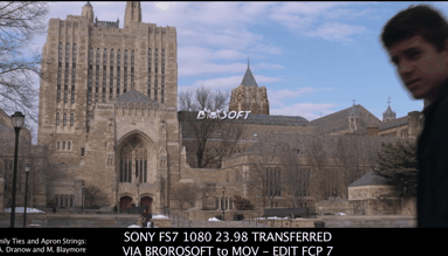

00065/0799 | magnitude=33.09757



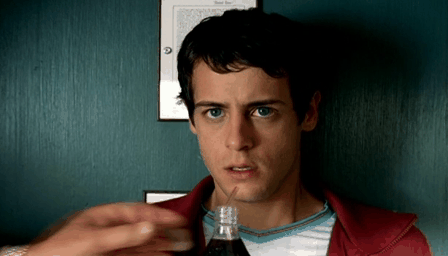

00028/0903 | magnitude=29.30275



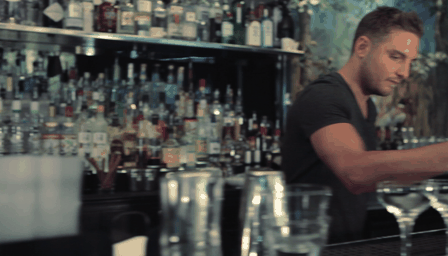

TOP 3 BY ANGULAR_VARIANCE
00017/0652 | angular_variance=0.04823



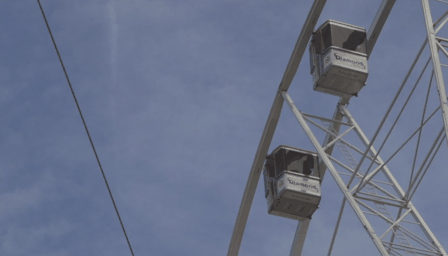

00023/0288 | angular_variance=0.04554



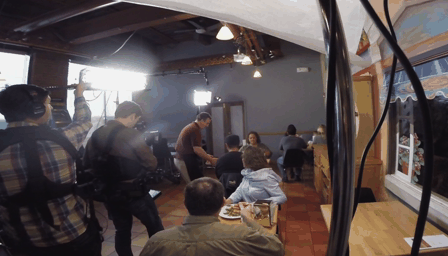

00055/0947 | angular_variance=0.04299



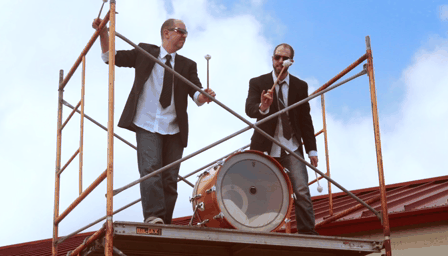

TOP 3 BY OCCLUSION_RATIO
00012/0576 | occlusion_ratio=0.41672



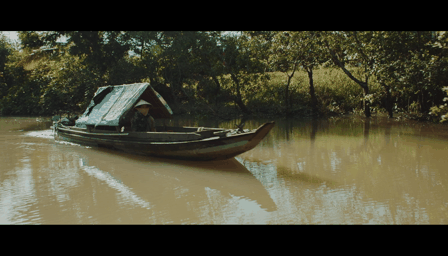

00025/0440 | occlusion_ratio=0.39768



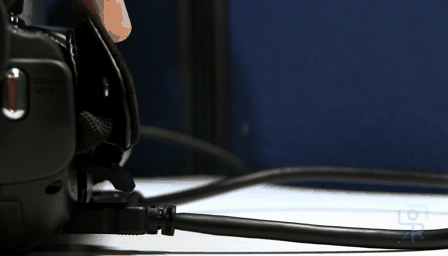

00031/0990 | occlusion_ratio=0.38700



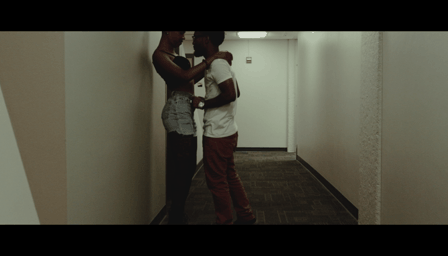

TOP 3 BY NON_RIGIDITY_ORIGINAL
00033/0957 | non_rigidity_original=1.10152



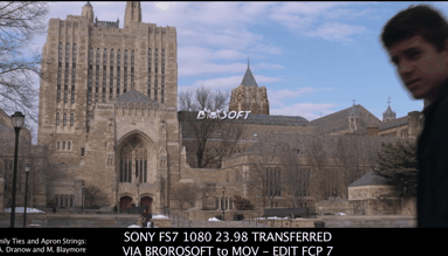

00030/0503 | non_rigidity_original=0.97637



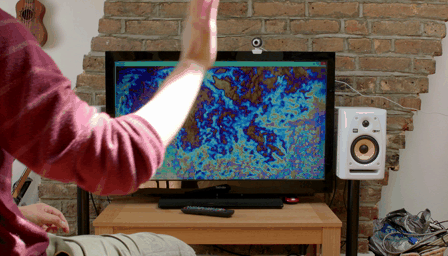

00078/0217 | non_rigidity_original=0.94461



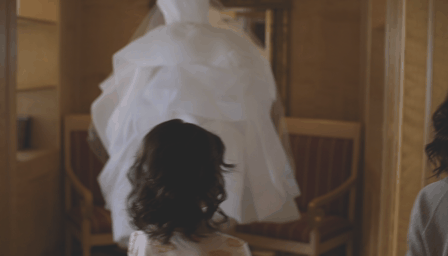

TOP 3 BY NON_RIGIDITY_IMPROVED
00055/0947 | non_rigidity_improved=0.30060



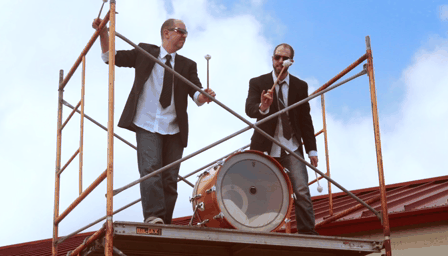

00047/0045 | non_rigidity_improved=0.21045



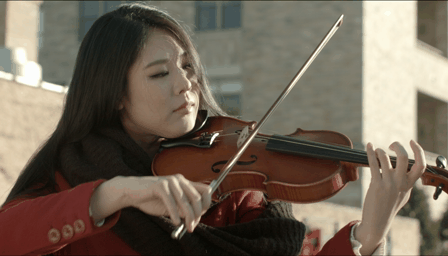

00023/0288 | non_rigidity_improved=0.20079



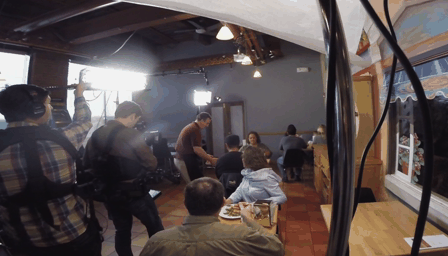

In [20]:
show_top_gifs("magnitude", 3)
show_top_gifs("angular_variance", 3)
show_top_gifs("occlusion_ratio", 3)
show_top_gifs("non_rigidity_original", 3)
show_top_gifs("non_rigidity_improved", 3)

# ***BATCH PROCESSING***

In [24]:
# ---------------------------------------------------------------------------
# HISTORICAL / RETAINED FOR AUDIT ONLY
# Earlier descriptor-processing implementation. It is retained with its outputs
# for provenance and is not the final 170-clip calibration/classification path.
# ---------------------------------------------------------------------------
# import os
# import time
# import json
# import logging
# import numpy as np
# import pandas as pd
# import torch
# from PIL import Image
# from collections import defaultdict
# from torch.utils.data import Dataset, DataLoader
# from tqdm.auto import tqdm

# import warnings

# warnings.filterwarnings(
#     "ignore",
#     message=r"`torch\.cuda\.amp\.autocast.*is deprecated.*",
#     category=FutureWarning
# )

# # ============================================================
# # PATHS
# # ============================================================
# VIMEO_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet"
# # `splits` / SPLITS_PATH already loaded earlier in this notebook from the
# # shared split dataset -- reused here, not re-derived.

# CATALOG_DIR = "/kaggle/working/catalog"
# LOG_DIR = "/kaggle/working/logs"
# os.makedirs(CATALOG_DIR, exist_ok=True)
# os.makedirs(LOG_DIR, exist_ok=True)

# OUTPUT_PATH = f"{CATALOG_DIR}/raft_descriptors.csv"

# # Fixed output schema -- no motion-category classification and no choice
# # between non-rigidity variants happens in this notebook. Both raw
# # non-rigidity descriptors are preserved as-is for calibration later.
# OUTPUT_COLUMNS = [
#     "clip_id",
#     "magnitude",
#     "p90_magnitude",
#     "active_pixel_ratio",
#     "angular_variance",
#     "occlusion_ratio",
#     "mean_fb_error",
#     "mean_relative_fb_error",
#     "non_rigidity_original",
#     "non_rigidity_improved",
#     "status",
#     "time_sec"
# ]

# # ============================================================
# # LOGGING
# # ============================================================
# logger = logging.getLogger("raft_batch")
# logger.setLevel(logging.INFO)
# logger.handlers.clear()

# fh = logging.FileHandler(f"{LOG_DIR}/raft_batch_run.log")
# fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
# ch = logging.StreamHandler()
# ch.setFormatter(logging.Formatter("%(message)s"))
# logger.addHandler(fh)
# logger.addHandler(ch)

# # ============================================================
# # TEST SPLIT -- from the shared splits.csv established once and reused across all notebooks in this project
# # ============================================================
# test_ids = splits.loc[splits["split"] == "test", "clip_id"].tolist()
# logger.info(f"Test clips to process: {len(test_ids)}")

# # ============================================================
# # DATASET (Vimeo clips are uniformly 256x448 -- single bucket, but
# # InputPadder is still applied for safety/consistency)
# # ============================================================
# class VimeoRaftDataset(Dataset):
#     def __init__(self, clip_ids):
#         self.clip_ids = clip_ids

#     def __len__(self):
#         return len(self.clip_ids)

#     def __getitem__(self, idx):
#         clip_id = self.clip_ids[idx]
#         clip_dir = os.path.join(VIMEO_ROOT, "sequences", clip_id)
#         im1 = np.array(Image.open(f"{clip_dir}/im1.png").convert("RGB"))
#         im3 = np.array(Image.open(f"{clip_dir}/im3.png").convert("RGB"))
#         t1 = torch.from_numpy(im1).permute(2, 0, 1).float()
#         t3 = torch.from_numpy(im3).permute(2, 0, 1).float()
#         return clip_id, t1, t3

# # ============================================================
# # RESUME SUPPORT (failed clips retried, not skipped)
# # ============================================================
# if os.path.exists(OUTPUT_PATH):
#     done_df = pd.read_csv(OUTPUT_PATH)
#     done_ids = set(done_df.loc[done_df["status"] == "success", "clip_id"])
#     results = done_df[done_df["status"] == "success"].to_dict("records")
#     logger.info(f"Resuming: {len(done_ids)} successful clips already done.")
# else:
#     done_ids = set()
#     results = []

# remaining_ids = [c for c in test_ids if c not in done_ids]
# logger.info(f"Remaining to process: {len(remaining_ids)}")

# # ============================================================
# # BATCH LOOP
# # ============================================================
# BATCH_SIZE = 8
# NUM_WORKERS = 2
# CHECKPOINT_EVERY_N_BATCHES = 5

# ds = VimeoRaftDataset(remaining_ids)
# dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
#                  num_workers=NUM_WORKERS, pin_memory=True)

# pbar = tqdm(total=len(test_ids), initial=len(done_ids), unit="clip", desc="RAFT descriptors")
# processed = len(done_ids)
# batch_start = time.time()

# for batch_num, (clip_ids, im1_b, im3_b) in enumerate(dl, start=1):
#     t0 = time.perf_counter()
#     try:
#         im1_b = im1_b.to(DEVICE, non_blocking=True)
#         im3_b = im3_b.to(DEVICE, non_blocking=True)

#         padder = InputPadder(im1_b.shape, mode="sintel")
#         im1_p, im3_p = padder.pad(im1_b, im3_b)

#         with torch.no_grad():
#             _, flow_fwd = raft_model(im1_p, im3_p, iters=20, test_mode=True)
#             _, flow_bwd = raft_model(im3_p, im1_p, iters=20, test_mode=True)

#         flow_fwd = padder.unpad(flow_fwd)
#         flow_bwd = padder.unpad(flow_bwd)

#         # compute_descriptors returns both raw non-rigidity scores directly --
#         # no classification-facing value, no variant selection here.
#         desc = compute_descriptors(
#             flow_fwd, flow_bwd,
#             kernel_size=KERNEL_SIZE,
#             magnitude_threshold=MAGNITUDE_THRESHOLD,
#             mag_epsilon=MAG_EPSILON,
#             alpha=ALPHA, beta=BETA,
#             suppress_boundaries=False
#         )
#         elapsed_batch = time.perf_counter() - t0
#         per_clip_time = elapsed_batch / len(clip_ids)

#         for i, cid in enumerate(clip_ids):
#             results.append({
#                 "clip_id": cid,
#                 "magnitude": desc["primary"]["magnitude"][i].item(),
#                 "p90_magnitude": desc["secondary"]["p90_magnitude"][i].item(),
#                 "active_pixel_ratio": desc["secondary"]["active_pixel_ratio"][i].item(),
#                 "angular_variance": desc["primary"]["angular_variance"][i].item(),
#                 "occlusion_ratio": desc["primary"]["occlusion_ratio"][i].item(),
#                 "mean_fb_error": desc["secondary"]["mean_fb_error"][i].item(),
#                 "mean_relative_fb_error": desc["secondary"]["mean_relative_fb_error"][i].item(),
#                 "non_rigidity_original": desc["secondary"]["non_rigidity_original"][i].item(),
#                 "non_rigidity_improved": desc["secondary"]["non_rigidity_improved"][i].item(),
#                 "status": "success",
#                 "time_sec": per_clip_time
#             })

#         del im1_b, im3_b, im1_p, im3_p, flow_fwd, flow_bwd, desc
#         torch.cuda.empty_cache()

#     except Exception as e:
#         logger.error(f"BATCH FAILED (batch {batch_num}): {repr(e)}")
#         for cid in clip_ids:
#             results.append({
#                 "clip_id": cid,
#                 "magnitude": np.nan,
#                 "p90_magnitude": np.nan,
#                 "active_pixel_ratio": np.nan,
#                 "angular_variance": np.nan,
#                 "occlusion_ratio": np.nan,
#                 "mean_fb_error": np.nan,
#                 "mean_relative_fb_error": np.nan,
#                 "non_rigidity_original": np.nan,
#                 "non_rigidity_improved": np.nan,
#                 "status": "failed",
#                 "time_sec": time.perf_counter() - t0
#             })

#     processed += len(clip_ids)
#     pbar.update(len(clip_ids))

#     if batch_num % CHECKPOINT_EVERY_N_BATCHES == 0:
#         pd.DataFrame(results)[OUTPUT_COLUMNS].to_csv(OUTPUT_PATH, index=False)
#         elapsed = time.time() - batch_start
#         rate = (processed - len(done_ids)) / elapsed if elapsed > 0 else 0
#         eta = (len(test_ids) - processed) / rate if rate > 0 else float("nan")
#         pbar.set_postfix_str(f"rate={rate:.2f} clip/s ETA={eta/60:.1f}min")
#         logger.info(f"[{processed}/{len(test_ids)}] elapsed={elapsed/60:.1f}min "
#                     f"rate={rate:.2f} clips/s ETA={eta/60:.1f}min")

# pbar.close()

# # --------------------------------------------------------------
# # Final assembly -- enforce exact column set and order, no extras.
# # --------------------------------------------------------------
# final_df = pd.DataFrame(results)
# assert set(final_df.columns) == set(OUTPUT_COLUMNS), \
#     f"Unexpected columns: {set(final_df.columns) - set(OUTPUT_COLUMNS)}, " \
#     f"missing: {set(OUTPUT_COLUMNS) - set(final_df.columns)}"
# final_df = final_df[OUTPUT_COLUMNS]
# final_df.to_csv(OUTPUT_PATH, index=False)

# logger.info("========================================")
# logger.info("RAFT BATCH COMPLETE")
# logger.info("========================================")
# logger.info(f"Successful: {(final_df['status'] == 'success').sum()}")
# logger.info(f"Failed:     {(final_df['status'] == 'failed').sum()}")
# logger.info(f"Total time: {(time.time() - batch_start)/60:.2f} minutes")
# logger.info(f"Saved to:   {OUTPUT_PATH}")
# logger.info(f"Columns:    {list(final_df.columns)}")

# # Verification, per the required check
# expected_columns = [
#     "clip_id",
#     "magnitude",
#     "p90_magnitude",
#     "active_pixel_ratio",
#     "angular_variance",
#     "occlusion_ratio",
#     "mean_fb_error",
#     "mean_relative_fb_error",
#     "non_rigidity_original",
#     "non_rigidity_improved",
#     "status",
#     "time_sec"
# ]
# assert list(final_df.columns) == expected_columns, "Column order mismatch!"
# assert list(pd.read_csv(OUTPUT_PATH).columns) == expected_columns, "Saved CSV column order mismatch!"
# logger.info("Column check passed: CSV matches the required schema exactly.")

# manifest = {
#     "model": "RAFT",
#     "checkpoint": "raft-things.pth",
#     "role": "frozen optical-flow estimator for motion tagging only",
#     "split_source": SPLITS_PATH,
#     "config": {
#         "batch_size": BATCH_SIZE, "kernel_size": KERNEL_SIZE,
#         "magnitude_threshold": MAGNITUDE_THRESHOLD, "mag_epsilon": MAG_EPSILON,
#         "alpha": ALPHA, "beta": BETA
#     },
#     "note": "No motion-category classification and no non-rigidity variant "
#             "selection performed in this notebook -- both raw non-rigidity "
#             "scores (original, improved) are saved for calibration later.",
#     "counts": {
#         "total": int(len(final_df)),
#         "success": int((final_df["status"] == "success").sum()),
#         "failed": int((final_df["status"] == "failed").sum())
#     },
#     "files": {"descriptors": OUTPUT_PATH, "log": f"{LOG_DIR}/raft_batch_run.log"}
# }
# with open(f"{CATALOG_DIR}/raft_manifest.json", "w") as f:
#     json.dump(manifest, f, indent=2)
# logger.info(f"Saved manifest -> {CATALOG_DIR}/raft_manifest.json")


In [8]:
import os
import time
import json
import logging
import numpy as np
import pandas as pd
import torch
from PIL import Image
from collections import defaultdict
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

import warnings

warnings.filterwarnings(
    "ignore",
    message=r"`torch\.cuda\.amp\.autocast.*is deprecated.*",
    category=FutureWarning
)

# ============================================================
# PATHS
# ============================================================
VIMEO_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet"

CATALOG_DIR = "/kaggle/working/catalog"
LOG_DIR = "/kaggle/working/logs"
os.makedirs(CATALOG_DIR, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

OUTPUT_PATH = f"{CATALOG_DIR}/raft_descriptors_train.csv"

OUTPUT_COLUMNS = [
    "clip_id",
    "magnitude",
    "p90_magnitude",
    "active_pixel_ratio",
    "angular_variance",
    "occlusion_ratio",
    "mean_fb_error",
    "mean_relative_fb_error",
    "non_rigidity_original",
    "non_rigidity_improved",
    "status",
    "time_sec"
]

# ============================================================
# LOGGING
# ============================================================
logger = logging.getLogger("raft_batch_train")
logger.setLevel(logging.INFO)
logger.handlers.clear()

fh = logging.FileHandler(f"{LOG_DIR}/raft_batch_train_run.log")
fh.setFormatter(logging.Formatter("%(asctime)s %(levelname)s %(message)s"))
ch = logging.StreamHandler()
ch.setFormatter(logging.Formatter("%(message)s"))
logger.addHandler(fh)
logger.addHandler(ch)

# ============================================================
# TRAIN SPLIT -- from the shared splits.csv established once and reused across all notebooks in this project
# ============================================================
train_ids = splits.loc[splits["split"] == "train", "clip_id"].tolist()

logger.info(f"Train clips to process: {len(train_ids)}")

# ============================================================
# DATASET
# ============================================================
class VimeoRaftDataset(Dataset):
    def __init__(self, clip_ids):
        self.clip_ids = clip_ids

    def __len__(self):
        return len(self.clip_ids)

    def __getitem__(self, idx):
        clip_id = self.clip_ids[idx]
        clip_dir = os.path.join(VIMEO_ROOT, "sequences", clip_id)
        im1 = np.array(Image.open(f"{clip_dir}/im1.png").convert("RGB"))
        im3 = np.array(Image.open(f"{clip_dir}/im3.png").convert("RGB"))
        t1 = torch.from_numpy(im1).permute(2, 0, 1).float()
        t3 = torch.from_numpy(im3).permute(2, 0, 1).float()
        return clip_id, t1, t3

# ============================================================
# RESUME SUPPORT
# ============================================================
if os.path.exists(OUTPUT_PATH):
    done_df = pd.read_csv(OUTPUT_PATH)
    done_ids = set(done_df.loc[done_df["status"] == "success", "clip_id"])
    results = done_df[done_df["status"] == "success"].to_dict("records")
    logger.info(f"Resuming: {len(done_ids)} successful clips already done.")
else:
    done_ids = set()
    results = []

remaining_ids = [c for c in train_ids if c not in done_ids]
logger.info(f"Remaining to process: {len(remaining_ids)}")

# ============================================================
# BATCH LOOP
# ============================================================
BATCH_SIZE = 8
NUM_WORKERS = 2
CHECKPOINT_EVERY_N_BATCHES = 5

ds = VimeoRaftDataset(remaining_ids)
dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False,
                 num_workers=NUM_WORKERS, pin_memory=True)

pbar = tqdm(total=len(train_ids), initial=len(done_ids), unit="clip", desc="RAFT descriptors (train)")
processed = len(done_ids)
batch_start = time.time()

for batch_num, (clip_ids, im1_b, im3_b) in enumerate(dl, start=1):
    t0 = time.perf_counter()
    try:
        im1_b = im1_b.to(DEVICE, non_blocking=True)
        im3_b = im3_b.to(DEVICE, non_blocking=True)

        padder = InputPadder(im1_b.shape, mode="sintel")
        im1_p, im3_p = padder.pad(im1_b, im3_b)

        with torch.no_grad():
            _, flow_fwd = raft_model(im1_p, im3_p, iters=20, test_mode=True)
            _, flow_bwd = raft_model(im3_p, im1_p, iters=20, test_mode=True)

        flow_fwd = padder.unpad(flow_fwd)
        flow_bwd = padder.unpad(flow_bwd)

        desc = compute_descriptors(
            flow_fwd, flow_bwd,
            kernel_size=KERNEL_SIZE,
            magnitude_threshold=MAGNITUDE_THRESHOLD,
            mag_epsilon=MAG_EPSILON,
            alpha=ALPHA, beta=BETA,
            suppress_boundaries=False
        )
        elapsed_batch = time.perf_counter() - t0
        per_clip_time = elapsed_batch / len(clip_ids)

        for i, cid in enumerate(clip_ids):
            results.append({
                "clip_id": cid,
                "magnitude": desc["primary"]["magnitude"][i].item(),
                "p90_magnitude": desc["secondary"]["p90_magnitude"][i].item(),
                "active_pixel_ratio": desc["secondary"]["active_pixel_ratio"][i].item(),
                "angular_variance": desc["primary"]["angular_variance"][i].item(),
                "occlusion_ratio": desc["primary"]["occlusion_ratio"][i].item(),
                "mean_fb_error": desc["secondary"]["mean_fb_error"][i].item(),
                "mean_relative_fb_error": desc["secondary"]["mean_relative_fb_error"][i].item(),
                "non_rigidity_original": desc["secondary"]["non_rigidity_original"][i].item(),
                "non_rigidity_improved": desc["secondary"]["non_rigidity_improved"][i].item(),
                "status": "success",
                "time_sec": per_clip_time
            })

        del im1_b, im3_b, im1_p, im3_p, flow_fwd, flow_bwd, desc
        torch.cuda.empty_cache()

    except Exception as e:
        logger.error(f"BATCH FAILED (batch {batch_num}): {repr(e)}")
        for cid in clip_ids:
            results.append({
                "clip_id": cid,
                "magnitude": np.nan,
                "p90_magnitude": np.nan,
                "active_pixel_ratio": np.nan,
                "angular_variance": np.nan,
                "occlusion_ratio": np.nan,
                "mean_fb_error": np.nan,
                "mean_relative_fb_error": np.nan,
                "non_rigidity_original": np.nan,
                "non_rigidity_improved": np.nan,
                "status": "failed",
                "time_sec": time.perf_counter() - t0
            })

    processed += len(clip_ids)
    pbar.update(len(clip_ids))

    if batch_num % CHECKPOINT_EVERY_N_BATCHES == 0:
        pd.DataFrame(results)[OUTPUT_COLUMNS].to_csv(OUTPUT_PATH, index=False)
        elapsed = time.time() - batch_start
        rate = (processed - len(done_ids)) / elapsed if elapsed > 0 else 0
        eta = (len(train_ids) - processed) / rate if rate > 0 else float("nan")
        pbar.set_postfix_str(f"rate={rate:.2f} clip/s ETA={eta/60:.1f}min")
        logger.info(f"[{processed}/{len(train_ids)}] elapsed={elapsed/60:.1f}min "
                    f"rate={rate:.2f} clips/s ETA={eta/60:.1f}min")

pbar.close()

# --------------------------------------------------------------
# Final assembly
# --------------------------------------------------------------
final_df = pd.DataFrame(results)
assert set(final_df.columns) == set(OUTPUT_COLUMNS), \
    f"Unexpected columns: {set(final_df.columns) - set(OUTPUT_COLUMNS)}, " \
    f"missing: {set(OUTPUT_COLUMNS) - set(final_df.columns)}"
final_df = final_df[OUTPUT_COLUMNS]
final_df.to_csv(OUTPUT_PATH, index=False)

logger.info("========================================")
logger.info("RAFT BATCH COMPLETE (TRAIN SPLIT)")
logger.info("========================================")
logger.info(f"Successful: {(final_df['status'] == 'success').sum()}")
logger.info(f"Failed:     {(final_df['status'] == 'failed').sum()}")
logger.info(f"Total time: {(time.time() - batch_start)/60:.2f} minutes")
logger.info(f"Saved to:   {OUTPUT_PATH}")
logger.info(f"Columns:    {list(final_df.columns)}")

expected_columns = OUTPUT_COLUMNS
assert list(final_df.columns) == expected_columns, "Column order mismatch!"
assert list(pd.read_csv(OUTPUT_PATH).columns) == expected_columns, "Saved CSV column order mismatch!"
logger.info("Column check passed: CSV matches the required schema exactly.")

manifest = {
    "model": "RAFT",
    "checkpoint": "raft-things.pth",
    "role": "frozen optical-flow estimator for motion tagging only",
    "split": "train",
    "split_source": SPLIT_ROOT,
    "config": {
        "batch_size": BATCH_SIZE, "kernel_size": KERNEL_SIZE,
        "magnitude_threshold": MAGNITUDE_THRESHOLD, "mag_epsilon": MAG_EPSILON,
        "alpha": ALPHA, "beta": BETA
    },
    "note": "No motion-category classification and no non-rigidity variant "
            "selection performed in this notebook -- both raw non-rigidity "
            "scores (original, improved) are saved for calibration later.",
    "counts": {
        "total": int(len(final_df)),
        "success": int((final_df["status"] == "success").sum()),
        "failed": int((final_df["status"] == "failed").sum())
    },
    "files": {"descriptors": OUTPUT_PATH, "log": f"{LOG_DIR}/raft_batch_train_run.log"}
}
with open(f"{CATALOG_DIR}/raft_manifest_train.json", "w") as f:
    json.dump(manifest, f, indent=2)
logger.info(f"Saved manifest -> {CATALOG_DIR}/raft_manifest_train.json")

Train clips to process: 51324
Remaining to process: 51324


RAFT descriptors (train):   0%|          | 0/51324 [00:00<?, ?clip/s]

[40/51324] elapsed=0.2min rate=4.44 clips/s ETA=192.4min
[80/51324] elapsed=0.3min rate=4.91 clips/s ETA=174.0min
[120/51324] elapsed=0.4min rate=5.07 clips/s ETA=168.3min
[160/51324] elapsed=0.5min rate=5.14 clips/s ETA=165.8min
[200/51324] elapsed=0.6min rate=5.18 clips/s ETA=164.5min
[240/51324] elapsed=0.8min rate=5.19 clips/s ETA=163.9min
[280/51324] elapsed=0.9min rate=5.19 clips/s ETA=163.9min
[320/51324] elapsed=1.0min rate=5.19 clips/s ETA=163.9min
[360/51324] elapsed=1.2min rate=5.18 clips/s ETA=164.0min
[400/51324] elapsed=1.3min rate=5.18 clips/s ETA=163.9min
[440/51324] elapsed=1.4min rate=5.18 clips/s ETA=163.6min
[480/51324] elapsed=1.5min rate=5.19 clips/s ETA=163.3min
[520/51324] elapsed=1.7min rate=5.20 clips/s ETA=162.9min
[560/51324] elapsed=1.8min rate=5.20 clips/s ETA=162.6min
[600/51324] elapsed=1.9min rate=5.21 clips/s ETA=162.3min
[640/51324] elapsed=2.0min rate=5.22 clips/s ETA=162.0min
[680/51324] elapsed=2.2min rate=5.22 clips/s ETA=161.7min
[720/51324] elap

KeyboardInterrupt: 

In [9]:
# ============================================================
# TRUE 2x T4 GPU RAFT EXTRACTION
# ============================================================

import copy
import threading
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

BATCH_SIZE = 16
NUM_WORKERS = 2
CHECKPOINT_EVERY_N_BATCHES = 5
MAX_GPU_RETRIES = 1

GPU_IDS = [0, 1]

# ============================================================
# LOAD EXISTING RESULTS
# ============================================================

if os.path.exists(OUTPUT_PATH):
    existing_df = pd.read_csv(OUTPUT_PATH)

    existing_success = existing_df[
        existing_df["status"] == "success"
    ].copy()

    done_ids = set(existing_success["clip_id"].astype(str))

    logger.info(
        f"Existing successful clips: {len(done_ids)}"
    )
else:
    existing_success = pd.DataFrame(columns=OUTPUT_COLUMNS)
    done_ids = set()

# Only process clips not already successful
remaining_ids = [
    str(c) for c in train_ids
    if str(c) not in done_ids
]

logger.info(
    f"Remaining clips: {len(remaining_ids)}"
)

if len(remaining_ids) == 0:
    logger.info("Nothing left to process.")
else:

    # ========================================================
    # SPLIT WORK BETWEEN TWO GPUS
    # ========================================================

    gpu0_ids = remaining_ids[0::2]
    gpu1_ids = remaining_ids[1::2]

    gpu_work = {
        0: gpu0_ids,
        1: gpu1_ids
    }

    logger.info(
        f"GPU 0 clips: {len(gpu0_ids)}"
    )
    logger.info(
        f"GPU 1 clips: {len(gpu1_ids)}"
    )

    # ========================================================
    # CREATE TWO INDEPENDENT MODEL COPIES
    # ========================================================

    logger.info("Creating independent RAFT model copies...")

    # Keep original notebook model untouched.
    base_model = copy.deepcopy(raft_model).cpu()
    base_model.eval()

    raft_gpu0 = copy.deepcopy(base_model).to("cuda:0").eval()
    raft_gpu1 = copy.deepcopy(base_model).to("cuda:1").eval()

    del base_model
    torch.cuda.empty_cache()

    logger.info("RAFT models loaded on both T4 GPUs.")

    # ========================================================
    # PER-CLIP PROCESSING
    # ========================================================

    def process_single_clip(
        model,
        device,
        clip_id
    ):
        t0 = time.perf_counter()

        clip_dir = os.path.join(
            VIMEO_ROOT,
            "sequences",
            clip_id
        )

        im1 = np.array(
            Image.open(
                f"{clip_dir}/im1.png"
            ).convert("RGB")
        )

        im3 = np.array(
            Image.open(
                f"{clip_dir}/im3.png"
            ).convert("RGB")
        )

        im1_t = torch.from_numpy(
            im1
        ).permute(2, 0, 1).float().unsqueeze(0)

        im3_t = torch.from_numpy(
            im3
        ).permute(2, 0, 1).float().unsqueeze(0)

        im1_t = im1_t.to(
            device,
            non_blocking=True
        )

        im3_t = im3_t.to(
            device,
            non_blocking=True
        )

        padder = InputPadder(
            im1_t.shape,
            mode="sintel"
        )

        im1_p, im3_p = padder.pad(
            im1_t,
            im3_t
        )

        with torch.inference_mode():

            _, flow_fwd = model(
                im1_p,
                im3_p,
                iters=20,
                test_mode=True
            )

            _, flow_bwd = model(
                im3_p,
                im1_p,
                iters=20,
                test_mode=True
            )

        flow_fwd = padder.unpad(flow_fwd)
        flow_bwd = padder.unpad(flow_bwd)

        desc = compute_descriptors(
            flow_fwd,
            flow_bwd,
            kernel_size=KERNEL_SIZE,
            magnitude_threshold=MAGNITUDE_THRESHOLD,
            mag_epsilon=MAG_EPSILON,
            alpha=ALPHA,
            beta=BETA,
            suppress_boundaries=False
        )

        elapsed = time.perf_counter() - t0

        result = {
            "clip_id": clip_id,
            "magnitude":
                desc["primary"]["magnitude"][0].item(),

            "p90_magnitude":
                desc["secondary"]["p90_magnitude"][0].item(),

            "active_pixel_ratio":
                desc["secondary"]["active_pixel_ratio"][0].item(),

            "angular_variance":
                desc["primary"]["angular_variance"][0].item(),

            "occlusion_ratio":
                desc["primary"]["occlusion_ratio"][0].item(),

            "mean_fb_error":
                desc["secondary"]["mean_fb_error"][0].item(),

            "mean_relative_fb_error":
                desc["secondary"]["mean_relative_fb_error"][0].item(),

            "non_rigidity_original":
                desc["secondary"]["non_rigidity_original"][0].item(),

            "non_rigidity_improved":
                desc["secondary"]["non_rigidity_improved"][0].item(),

            "status": "success",
            "time_sec": elapsed
        }

        del (
            im1_t,
            im3_t,
            im1_p,
            im3_p,
            flow_fwd,
            flow_bwd,
            desc
        )

        return result

    # ========================================================
    # GPU WORKER
    # ========================================================

    def gpu_worker(gpu_id):

        device = torch.device(
            f"cuda:{gpu_id}"
        )

        model = (
            raft_gpu0
            if gpu_id == 0
            else raft_gpu1
        )

        clip_ids = gpu_work[gpu_id]

        if not clip_ids:
            return []

        logger.info(
            f"GPU {gpu_id}: starting "
            f"{len(clip_ids)} clips"
        )

        dataset = VimeoRaftDataset(
            clip_ids
        )

        loader = DataLoader(
            dataset,
            batch_size=BATCH_SIZE,
            shuffle=False,
            num_workers=NUM_WORKERS,
            pin_memory=True,
            persistent_workers=True
        )

        gpu_output = []

        checkpoint_path = (
            f"{CATALOG_DIR}/"
            f"raft_train_gpu{gpu_id}_checkpoint.csv"
        )

        # Resume worker-specific checkpoint too
        if os.path.exists(checkpoint_path):

            old_gpu = pd.read_csv(
                checkpoint_path
            )

            old_gpu = old_gpu[
                old_gpu["status"] == "success"
            ]

            worker_done = set(
                old_gpu["clip_id"].astype(str)
            )

            gpu_output = (
                old_gpu[
                    OUTPUT_COLUMNS
                ].to_dict("records")
            )

            logger.info(
                f"GPU {gpu_id}: "
                f"resuming {len(worker_done)} clips"
            )

        else:
            worker_done = set()

        processed = len(worker_done)

        pbar = tqdm(
            total=len(clip_ids),
            initial=processed,
            desc=f"T4 GPU {gpu_id}",
            unit="clip"
        )

        for batch_num, (
            batch_clip_ids,
            im1_b,
            im3_b
        ) in enumerate(
            loader,
            start=1
        ):

            batch_clip_ids = [
                str(x)
                for x in batch_clip_ids
            ]

            # Remove clips already in worker checkpoint
            new_ids = [
                x for x in batch_clip_ids
                if x not in worker_done
            ]

            if not new_ids:
                pbar.update(
                    len(batch_clip_ids)
                )
                continue

            batch_t0 = time.perf_counter()

            try:

                # ============================================
                # NORMAL BATCH PROCESSING
                # ============================================

                im1_b = im1_b.to(
                    device,
                    non_blocking=True
                )

                im3_b = im3_b.to(
                    device,
                    non_blocking=True
                )

                padder = InputPadder(
                    im1_b.shape,
                    mode="sintel"
                )

                im1_p, im3_p = padder.pad(
                    im1_b,
                    im3_b
                )

                with torch.inference_mode():

                    _, flow_fwd = model(
                        im1_p,
                        im3_p,
                        iters=20,
                        test_mode=True
                    )

                    _, flow_bwd = model(
                        im3_p,
                        im1_p,
                        iters=20,
                        test_mode=True
                    )

                flow_fwd = padder.unpad(
                    flow_fwd
                )

                flow_bwd = padder.unpad(
                    flow_bwd
                )

                desc = compute_descriptors(
                    flow_fwd,
                    flow_bwd,
                    kernel_size=KERNEL_SIZE,
                    magnitude_threshold=MAGNITUDE_THRESHOLD,
                    mag_epsilon=MAG_EPSILON,
                    alpha=ALPHA,
                    beta=BETA,
                    suppress_boundaries=False
                )

                elapsed_batch = (
                    time.perf_counter()
                    - batch_t0
                )

                per_clip_time = (
                    elapsed_batch
                    / len(batch_clip_ids)
                )

                for i, cid in enumerate(
                    batch_clip_ids
                ):

                    result = {
                        "clip_id": cid,

                        "magnitude":
                            desc["primary"]["magnitude"][i].item(),

                        "p90_magnitude":
                            desc["secondary"]["p90_magnitude"][i].item(),

                        "active_pixel_ratio":
                            desc["secondary"]["active_pixel_ratio"][i].item(),

                        "angular_variance":
                            desc["primary"]["angular_variance"][i].item(),

                        "occlusion_ratio":
                            desc["primary"]["occlusion_ratio"][i].item(),

                        "mean_fb_error":
                            desc["secondary"]["mean_fb_error"][i].item(),

                        "mean_relative_fb_error":
                            desc["secondary"]["mean_relative_fb_error"][i].item(),

                        "non_rigidity_original":
                            desc["secondary"]["non_rigidity_original"][i].item(),

                        "non_rigidity_improved":
                            desc["secondary"]["non_rigidity_improved"][i].item(),

                        "status": "success",
                        "time_sec": per_clip_time
                    }

                    gpu_output.append(result)
                    worker_done.add(cid)

                del (
                    im1_b,
                    im3_b,
                    im1_p,
                    im3_p,
                    flow_fwd,
                    flow_bwd,
                    desc
                )

            except Exception as batch_error:

                logger.error(
                    f"GPU {gpu_id} "
                    f"batch {batch_num} failed: "
                    f"{repr(batch_error)}"
                )

                # ============================================
                # FALLBACK: PROCESS EACH CLIP INDIVIDUALLY
                # ============================================

                for cid in batch_clip_ids:

                    if cid in worker_done:
                        continue

                    success = False

                    for attempt in range(
                        MAX_GPU_RETRIES + 1
                    ):

                        try:

                            result = (
                                process_single_clip(
                                    model,
                                    device,
                                    cid
                                )
                            )

                            gpu_output.append(
                                result
                            )

                            worker_done.add(cid)
                            success = True

                            break

                        except Exception as e:

                            logger.error(
                                f"GPU {gpu_id} "
                                f"clip {cid} "
                                f"attempt {attempt + 1} "
                                f"failed: {repr(e)}"
                            )

                            torch.cuda.empty_cache()

                    if not success:

                        gpu_output.append({
                            "clip_id": cid,
                            "magnitude": np.nan,
                            "p90_magnitude": np.nan,
                            "active_pixel_ratio": np.nan,
                            "angular_variance": np.nan,
                            "occlusion_ratio": np.nan,
                            "mean_fb_error": np.nan,
                            "mean_relative_fb_error": np.nan,
                            "non_rigidity_original": np.nan,
                            "non_rigidity_improved": np.nan,
                            "status": "failed",
                            "time_sec": 0
                        })

            processed += len(batch_clip_ids)

            pbar.update(
                len(batch_clip_ids)
            )

            # ================================================
            # CHECKPOINT
            # ================================================

            if (
                batch_num
                % CHECKPOINT_EVERY_N_BATCHES
                == 0
            ):

                checkpoint_df = pd.DataFrame(
                    gpu_output
                )[OUTPUT_COLUMNS]

                checkpoint_df.to_csv(
                    checkpoint_path,
                    index=False
                )

                pbar.set_postfix(
                    processed=processed
                )

                logger.info(
                    f"GPU {gpu_id}: "
                    f"{processed}/{len(clip_ids)} "
                    f"checkpoint saved"
                )

        pbar.close()

        # Final worker checkpoint
        pd.DataFrame(
            gpu_output
        )[OUTPUT_COLUMNS].to_csv(
            checkpoint_path,
            index=False
        )

        logger.info(
            f"GPU {gpu_id}: COMPLETE "
            f"{len(gpu_output)} results"
        )

        return gpu_output

    # ========================================================
    # RUN BOTH GPUS SIMULTANEOUSLY
    # ========================================================

    logger.info(
        "========================================"
    )
    logger.info(
        "STARTING TRUE 2x T4 RAFT PROCESSING"
    )
    logger.info(
        "========================================"
    )

    total_start = time.time()

    with ThreadPoolExecutor(
        max_workers=2
    ) as executor:

        futures = {
            executor.submit(
                gpu_worker,
                gpu_id
            ): gpu_id
            for gpu_id in GPU_IDS
        }

        all_new_results = []

        for future in futures:

            gpu_id = futures[future]

            try:

                gpu_results = future.result()

                all_new_results.extend(
                    gpu_results
                )

                logger.info(
                    f"GPU {gpu_id} finished."
                )

            except Exception as e:

                logger.error(
                    f"GPU {gpu_id} worker crashed: "
                    f"{repr(e)}"
                )

    # ========================================================
    # MERGE OLD + NEW
    # ========================================================

    new_df = pd.DataFrame(
        all_new_results,
        columns=OUTPUT_COLUMNS
    )

    combined_df = pd.concat(
        [
            existing_success,
            new_df
        ],
        ignore_index=True
    )

    # Remove duplicates safely
    combined_df["clip_id"] = (
        combined_df["clip_id"].astype(str)
    )

    combined_df = (
        combined_df
        .drop_duplicates(
            subset=["clip_id"],
            keep="last"
        )
        .sort_values("clip_id")
        .reset_index(drop=True)
    )

    combined_df = combined_df[
        OUTPUT_COLUMNS
    ]

    combined_df.to_csv(
        OUTPUT_PATH,
        index=False
    )

    # ========================================================
    # FINAL CHECKS
    # ========================================================

    success_count = int(
        (combined_df["status"] == "success").sum()
    )

    failed_count = int(
        (combined_df["status"] == "failed").sum()
    )

    logger.info(
        "========================================"
    )
    logger.info(
        "2x T4 RAFT EXTRACTION COMPLETE"
    )
    logger.info(
        "========================================"
    )

    logger.info(
        f"Total results: {len(combined_df)}"
    )

    logger.info(
        f"Successful: {success_count}"
    )

    logger.info(
        f"Failed: {failed_count}"
    )

    logger.info(
        f"Total wall time: "
        f"{(time.time() - total_start)/60:.2f} minutes"
    )

    logger.info(
        f"Saved: {OUTPUT_PATH}"
    )

    assert list(
        combined_df.columns
    ) == OUTPUT_COLUMNS

    assert len(
        set(combined_df["clip_id"])
    ) == len(combined_df)

    logger.info(
        "Final validation passed."
    )

Existing successful clips: 2120
Remaining clips: 49204
GPU 0 clips: 24602
GPU 1 clips: 24602
Creating independent RAFT model copies...
RAFT models loaded on both T4 GPUs.
STARTING TRUE 2x T4 RAFT PROCESSING
GPU 0: starting 24602 clips
GPU 1: starting 24602 clips


T4 GPU 0:   0%|          | 0/24602 [00:00<?, ?clip/s]

T4 GPU 1:   0%|          | 0/24602 [00:00<?, ?clip/s]

GPU 1: 80/24602 checkpoint saved
GPU 0: 80/24602 checkpoint saved
GPU 1: 160/24602 checkpoint saved
GPU 0: 160/24602 checkpoint saved
GPU 1: 240/24602 checkpoint saved
GPU 0: 240/24602 checkpoint saved
GPU 1: 320/24602 checkpoint saved
GPU 0: 320/24602 checkpoint saved
GPU 1: 400/24602 checkpoint saved
GPU 0: 400/24602 checkpoint saved
GPU 1: 480/24602 checkpoint saved
GPU 0: 480/24602 checkpoint saved
GPU 1: 560/24602 checkpoint saved
GPU 0: 560/24602 checkpoint saved
GPU 1: 640/24602 checkpoint saved
GPU 0: 640/24602 checkpoint saved
GPU 1: 720/24602 checkpoint saved
GPU 0: 720/24602 checkpoint saved
GPU 1: 800/24602 checkpoint saved
GPU 0: 800/24602 checkpoint saved
GPU 1: 880/24602 checkpoint saved
GPU 0: 880/24602 checkpoint saved
GPU 1: 960/24602 checkpoint saved
GPU 0: 960/24602 checkpoint saved
GPU 1: 1040/24602 checkpoint saved
GPU 0: 1040/24602 checkpoint saved
GPU 1: 1120/24602 checkpoint saved
GPU 0: 1120/24602 checkpoint saved
GPU 1: 1200/24602 checkpoint saved
GPU 0: 1200

In [22]:
# # ============================================================
# # CREATE + DOWNLOAD ALL 170 CALIBRATION GIFS
# # ============================================================

# import os
# import zipfile
# import pandas as pd
# import imageio.v2 as imageio
# from IPython.display import FileLink, display

# # ------------------------------------------------------------
# # Paths
# # ------------------------------------------------------------
# DESC_CSV = "/kaggle/working/vimeo_170_motion_descriptors.csv"

# DATASET_ROOT = (
#     "/kaggle/input/datasets/chenshu123/"
#     "vimeo-triplet/vimeo_triplet/sequences"
# )

# GIF_DIR = "/kaggle/working/calibration_gifs"
# ZIP_PATH = "/kaggle/working/calibration_170_gifs.zip"

# os.makedirs(GIF_DIR, exist_ok=True)

# # ------------------------------------------------------------
# # Load 50 calibration clips
# # ------------------------------------------------------------
# df = pd.read_csv(DESC_CSV)

# clip_ids = df["clip_id"].astype(str).tolist()

# print(f"Found {len(clip_ids)} calibration clips.")

# # ------------------------------------------------------------
# # Create GIFs
# # ------------------------------------------------------------
# created = 0
# failed = []

# for i, clip_id in enumerate(clip_ids, 1):

#     # IMPORTANT:
#     # clip_id contains "/" because Vimeo IDs are like:
#     # 00001/0622
#     #
#     # Use it normally for the SOURCE path.
#     clip_dir = os.path.join(DATASET_ROOT, clip_id)

#     im1_path = os.path.join(clip_dir, "im1.png")
#     im2_path = os.path.join(clip_dir, "im2.png")
#     im3_path = os.path.join(clip_dir, "im3.png")

#     # Replace "/" only for the OUTPUT filename
#     safe_id = clip_id.replace("/", "_")

#     output_gif = os.path.join(
#         GIF_DIR,
#         f"{i:02d}_{safe_id}.gif"
#     )

#     try:

#         if not os.path.exists(im1_path):
#             raise FileNotFoundError(im1_path)

#         if not os.path.exists(im2_path):
#             raise FileNotFoundError(im2_path)

#         if not os.path.exists(im3_path):
#             raise FileNotFoundError(im3_path)

#         im1 = imageio.imread(im1_path)
#         im2 = imageio.imread(im2_path)
#         im3 = imageio.imread(im3_path)

#         # I0 -> Igt -> I1 -> Igt -> I0
#         frames = [
#             im1,
#             im2,
#             im3,
#             im2,
#             im1
#         ]

#         imageio.mimsave(
#             output_gif,
#             frames,
#             duration=0.35,
#             loop=0
#         )

#         created += 1

#         print(f"[{i:02d}/50] Created {safe_id}.gif")

#     except Exception as e:

#         failed.append((clip_id, str(e)))

#         print(
#             f"[{i:02d}/50] FAILED {clip_id}: {e}"
#         )

# # ------------------------------------------------------------
# # Create ZIP
# # ------------------------------------------------------------
# print("\nCreating ZIP...")

# with zipfile.ZipFile(
#     ZIP_PATH,
#     "w",
#     compression=zipfile.ZIP_DEFLATED
# ) as z:

#     for filename in sorted(os.listdir(GIF_DIR)):

#         if filename.endswith(".gif"):

#             path = os.path.join(
#                 GIF_DIR,
#                 filename
#             )

#             z.write(
#                 path,
#                 arcname=filename
#             )

# # ------------------------------------------------------------
# # Results
# # ------------------------------------------------------------
# print("\n========================================")
# print("DONE")
# print("========================================")

# print(f"GIFs created : {created}/50")
# print(f"Failed       : {len(failed)}")

# if os.path.exists(ZIP_PATH):

#     size_mb = os.path.getsize(ZIP_PATH) / (1024 ** 2)

#     print(f"ZIP size     : {size_mb:.2f} MB")

# if failed:

#     print("\nFailed clips:")

#     for clip_id, error in failed:
#         print(f"{clip_id} -> {error}")

# else:

#     print("\nAll 170 GIFs created successfully.")

# print("\nDownload the ZIP:")
# display(FileLink(ZIP_PATH))

In [23]:
# # ============================================================
# # NON-BLOCKING CALIBRATION LABELING UI
# # ============================================================

# import os
# import pandas as pd
# import matplotlib.pyplot as plt
# from PIL import Image
# from IPython.display import display, clear_output
# import ipywidgets as widgets

# # ------------------------------------------------------------
# # Paths
# # ------------------------------------------------------------
# DESC_CSV = "/kaggle/working/vimeo_170_motion_descriptors.csv"
# LABEL_CSV = "/kaggle/working/calibration_manual_labels.csv"

# DATASET_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet/sequences"

# # ------------------------------------------------------------
# # Load descriptors
# # ------------------------------------------------------------
# desc_df = pd.read_csv(DESC_CSV)

# # ------------------------------------------------------------
# # Load existing labels if available
# # ------------------------------------------------------------
# if os.path.exists(LABEL_CSV):
#     labels_df = pd.read_csv(LABEL_CSV)
# else:
#     labels_df = pd.DataFrame(columns=["clip_id", "manual_category"])

# # Make sure columns exist
# if "clip_id" not in labels_df.columns:
#     labels_df["clip_id"] = []

# if "manual_category" not in labels_df.columns:
#     labels_df["manual_category"] = []

# # Remove accidental duplicates
# labels_df = labels_df.drop_duplicates("clip_id", keep="last").reset_index(drop=True)

# # ------------------------------------------------------------
# # Categories
# # ------------------------------------------------------------
# CATEGORIES = {
#     "1": "near_linear",
#     "2": "rotation",
#     "3": "occlusion",
#     "4": "non_rigid",
# }

# # ------------------------------------------------------------
# # Find unlabeled clips
# # ------------------------------------------------------------
# def get_unlabeled():
#     labeled_ids = set(labels_df["clip_id"].astype(str))
#     return desc_df[
#         ~desc_df["clip_id"].astype(str).isin(labeled_ids)
#     ].reset_index(drop=True)

# unlabeled_df = get_unlabeled()

# # ------------------------------------------------------------
# # GIF/frame display
# # ------------------------------------------------------------
# def get_frame_path(clip_id, frame_name):
#     return os.path.join(
#         DATASET_ROOT,
#         clip_id,
#         frame_name + ".png"
#     )

# def show_clip(row):
#     clip_id = str(row["clip_id"])

#     frames = ["im1", "im2", "im3"]

#     fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#     for ax, frame_name in zip(axes, frames):
#         path = get_frame_path(clip_id, frame_name)

#         if os.path.exists(path):
#             img = Image.open(path)
#             ax.imshow(img)
#             ax.set_title(frame_name)
#         else:
#             ax.text(
#                 0.5, 0.5,
#                 f"Missing:\n{frame_name}",
#                 ha="center",
#                 va="center"
#             )

#         ax.axis("off")

#     plt.tight_layout()
#     plt.show()


# # ------------------------------------------------------------
# # UI
# # ------------------------------------------------------------
# output = widgets.Output()

# title = widgets.HTML()

# btn_linear = widgets.Button(
#     description="1 — Near Linear",
#     button_style=""
# )

# btn_rotation = widgets.Button(
#     description="2 — Rotation",
#     button_style=""
# )

# btn_occlusion = widgets.Button(
#     description="3 — Occlusion",
#     button_style=""
# )

# btn_nonrigid = widgets.Button(
#     description="4 — Non-Rigid",
#     button_style=""
# )

# btn_skip = widgets.Button(
#     description="Skip",
#     button_style="warning"
# )

# btn_quit = widgets.Button(
#     description="Save & Exit",
#     button_style="danger"
# )

# buttons = widgets.HBox([
#     btn_linear,
#     btn_rotation,
#     btn_occlusion,
#     btn_nonrigid,
#     btn_skip,
#     btn_quit
# ])

# # ------------------------------------------------------------
# # Current clip index
# # ------------------------------------------------------------
# current_index = 0


# def refresh_unlabeled():
#     global unlabeled_df
#     unlabeled_df = get_unlabeled()


# def display_current():
#     global current_index

#     refresh_unlabeled()

#     with output:
#         clear_output(wait=True)

#         if len(unlabeled_df) == 0:
#             print("====================================")
#             print("ALL 50 CALIBRATION CLIPS LABELED")
#             print("====================================")
#             print(f"Saved to: {LABEL_CSV}")
#             return

#         if current_index >= len(unlabeled_df):
#             current_index = 0

#         row = unlabeled_df.iloc[current_index]

#         clip_id = str(row["clip_id"])

#         title.value = f"""
#         <h3>Clip {current_index + 1} / {len(unlabeled_df)}</h3>
#         <b>clip_id:</b> {clip_id}
#         """

#         print("Descriptor values:")
#         print(f"  Magnitude:             {row['magnitude']:.6f}")
#         print(f"  P90 Magnitude:         {row['p90_magnitude']:.6f}")
#         print(f"  Active Pixel Ratio:    {row['active_pixel_ratio']:.6f}")
#         print(f"  Angular Variance:      {row['angular_variance']:.6f}")
#         print(f"  Occlusion Ratio:       {row['occlusion_ratio']:.6f}")
#         print(f"  Mean FB Error:         {row['mean_fb_error']:.6f}")
#         print(f"  Mean Relative FB:      {row['mean_relative_fb_error']:.6f}")
#         print(f"  Non-Rigid Original:    {row['non_rigidity_original']:.6f}")
#         print(f"  Non-Rigid Improved:    {row['non_rigidity_improved']:.6f}")
#         print()

#         show_clip(row)


# # ------------------------------------------------------------
# # Save label
# # ------------------------------------------------------------
# def save_label(category):
#     global current_index, labels_df

#     refresh_unlabeled()

#     if len(unlabeled_df) == 0:
#         return

#     row = unlabeled_df.iloc[current_index]
#     clip_id = str(row["clip_id"])

#     # Remove existing label if somehow present
#     labels_df = labels_df[
#         labels_df["clip_id"].astype(str) != clip_id
#     ]

#     # Add new label
#     new_row = pd.DataFrame([{
#         "clip_id": clip_id,
#         "manual_category": category
#     }])

#     labels_df = pd.concat(
#         [labels_df, new_row],
#         ignore_index=True
#     )

#     labels_df.to_csv(LABEL_CSV, index=False)

#     current_index = 0

#     display_current()


# # ------------------------------------------------------------
# # Button callbacks
# # ------------------------------------------------------------
# def on_linear(b):
#     save_label("near_linear")

# def on_rotation(b):
#     save_label("rotation")

# def on_occlusion(b):
#     save_label("occlusion")

# def on_nonrigid(b):
#     save_label("non_rigid")

# def on_skip(b):
#     global current_index

#     refresh_unlabeled()

#     if len(unlabeled_df) == 0:
#         return

#     current_index += 1

#     if current_index >= len(unlabeled_df):
#         current_index = 0

#     display_current()

# def on_quit(b):
#     with output:
#         clear_output(wait=True)

#         labels_df.to_csv(LABEL_CSV, index=False)

#         print("Saved!")
#         print(f"Labels completed: {len(labels_df)}")
#         print(f"File: {LABEL_CSV}")
#         print()
#         print("You can safely run another cell now.")


# btn_linear.on_click(on_linear)
# btn_rotation.on_click(on_rotation)
# btn_occlusion.on_click(on_occlusion)
# btn_nonrigid.on_click(on_nonrigid)
# btn_skip.on_click(on_skip)
# btn_quit.on_click(on_quit)

# # ------------------------------------------------------------
# # Start UI
# # ------------------------------------------------------------
# display(title)
# display(buttons)
# display(output)

# display_current()

In [32]:
import os

path = "/kaggle/working/calibration_manual_labels.csv"

if os.path.exists(path):
    os.remove(path)
    print("Deleted. Calibration labeling will start from scratch.")
else:
    print("File not found.")

Deleted. Calibration labeling will start from scratch.


# ***Classification***

In [26]:
# ---------------------------------------------------------------------------
# HISTORICAL CALIBRATION EXPLORATION
# The cells in this section contain earlier inspection, threshold, and model
# comparisons retained for faculty review. They are not the final source of the
# categories used in the reported training/test CSVs.
# The authoritative final calibration search starts at the later cell headed
# "AUTOMATIC DESCRIPTOR + CLASSIFIER SEARCH".
# ---------------------------------------------------------------------------
import pandas as pd
import os

BASE = "/kaggle/input/datasets/hibro00/vfi-csvs"

splits = pd.read_csv(os.path.join(BASE, "splits.csv"))
raft = pd.read_csv(os.path.join(BASE, "raft_descriptors.csv"))
labels = pd.read_csv(os.path.join(BASE, "calibration_manual_labels.csv"))

print("SPLITS")
print(splits.columns.tolist())
print(splits["split"].value_counts())

print("\nRAFT")
print("Rows:", len(raft))
print("Unique clips:", raft["clip_id"].nunique())

print("\nLABELS")
print("Rows:", len(labels))
print("Unique clips:", labels["clip_id"].nunique())

# ------------------------------------------------------------
# Check how many calibration IDs exist in RAFT CSV
# ------------------------------------------------------------

calib_ids = set(
    splits.loc[
        splits["split"].astype(str).str.lower().isin(
            ["calibration", "calib"]
        ),
        "clip_id"
    ].astype(str)
)

raft_ids = set(raft["clip_id"].astype(str))
label_ids = set(labels["clip_id"].astype(str))

print("\n" + "=" * 60)
print("CALIBRATION IDs IN SPLITS:", len(calib_ids))
print("CALIBRATION IDs WITH RAFT DESCRIPTORS:", len(calib_ids & raft_ids))
print("CALIBRATION IDs WITH MANUAL LABELS:", len(calib_ids & label_ids))

print("\nExample calibration IDs:")
print(list(calib_ids)[:10])

SPLITS
['clip_id', 'split']
split
train          51324
test            3601
calibration      170
Name: count, dtype: int64

RAFT
Rows: 3732
Unique clips: 3732

LABELS
Rows: 170
Unique clips: 170

CALIBRATION IDs IN SPLITS: 170
CALIBRATION IDs WITH RAFT DESCRIPTORS: 131
CALIBRATION IDs WITH MANUAL LABELS: 170

Example calibration IDs:
['00008/0263', '00034/0942', '00013/0553', '00010/0663', '00044/0795', '00050/0382', '00055/0948', '00016/0317', '00055/0671', '00013/0986']


In [29]:
import os
import pandas as pd

BASE = "/kaggle/input/datasets/hibro00/vfi-csvs"

raft_cal = pd.read_csv(
    os.path.join(BASE, "vimeo_170_motion_descriptors.csv")
)

labels = pd.read_csv(
    os.path.join(BASE, "calibration_manual_labels.csv")
)

print("Calibration descriptors:", len(raft_cal))
print("Manual labels:", len(labels))

print("\nCalibration descriptor columns:")
print(raft_cal.columns.tolist())

print("\nManual label columns:")
print(labels.columns.tolist())

Calibration descriptors: 170
Manual labels: 170

Calibration descriptor columns:
['clip_id', 'magnitude', 'p90_magnitude', 'active_pixel_ratio', 'angular_variance', 'occlusion_ratio', 'mean_fb_error', 'mean_relative_fb_error', 'non_rigidity_original', 'non_rigidity_improved', 'status', 'time_sec']

Manual label columns:
['clip_id', 'manual_category']


In [30]:
# ============================================================
# MATCH 170 RAFT DESCRIPTORS WITH 170 MANUAL LABELS
# ============================================================

cal = raft_cal.merge(
    labels,
    on="clip_id",
    how="outer",
    indicator=True
)

print("Merge status:")
print(cal["_merge"].value_counts())

# Check for anything that didn't match
missing_descriptors = cal.loc[
    cal["_merge"] == "right_only", "clip_id"
].tolist()

missing_labels = cal.loc[
    cal["_merge"] == "left_only", "clip_id"
].tolist()

print("\nMissing descriptors:", len(missing_descriptors))
print("Missing labels:", len(missing_labels))

if missing_descriptors:
    print("\nIDs with labels but no RAFT descriptors:")
    print(missing_descriptors)

if missing_labels:
    print("\nIDs with RAFT descriptors but no labels:")
    print(missing_labels)

# Keep only matched rows
cal = cal[
    cal["_merge"] == "both"
].drop(columns="_merge")

print("\n" + "=" * 50)
print("MATCHED CALIBRATION CLIPS:", len(cal))

print("\nManual categories:")
print(cal["manual_category"].value_counts())

Merge status:
_merge
both          170
left_only       0
right_only      0
Name: count, dtype: int64

Missing descriptors: 0
Missing labels: 0

MATCHED CALIBRATION CLIPS: 170

Manual categories:
manual_category
non_rigid      70
near_linear    55
rotation       24
occlusion      21
Name: count, dtype: int64


In [31]:
# ============================================================
# CALIBRATION — STANDARDIZATION + 75TH PERCENTILE
# ============================================================

import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

# ------------------------------------------------------------
# Descriptor mapping
# ------------------------------------------------------------

descriptor_map = {
    "near_linear": "magnitude",
    "rotation": "angular_variance",
    "occlusion": "occlusion_ratio",
    "non_rigid": "non_rigidity_original",
}

# ------------------------------------------------------------
# Standardize descriptors
# ------------------------------------------------------------

descriptor_cols = list(descriptor_map.values())

scaler = StandardScaler()

cal_z = cal.copy()

z_values = scaler.fit_transform(
    cal[descriptor_cols]
)

for i, col in enumerate(descriptor_cols):
    cal_z[col + "_z"] = z_values[:, i]

# ------------------------------------------------------------
# 75th percentile thresholds
# ------------------------------------------------------------

thresholds = {}

for category, descriptor in descriptor_map.items():

    z_col = descriptor + "_z"

    thresholds[category] = cal_z[z_col].quantile(0.75)

print("75th-percentile thresholds:")
print()

for category, threshold in thresholds.items():
    print(
        f"{category:12s} : "
        f"{threshold:.4f}"
    )

# ------------------------------------------------------------
# Automatic category assignment
# ------------------------------------------------------------

def classify_motion(row):

    candidates = {}

    for category, descriptor in descriptor_map.items():

        score = row[descriptor + "_z"]
        threshold = thresholds[category]

        if score >= threshold:
            candidates[category] = score

    # No threshold exceeded
    if not candidates:
        return "near_linear"

    # Highest standardized descriptor among
    # categories whose thresholds were exceeded
    return max(
        candidates,
        key=candidates.get
    )


cal_z["automatic_category"] = cal_z.apply(
    classify_motion,
    axis=1
)

# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\nAutomatic category counts:")
print(
    cal_z["automatic_category"]
    .value_counts()
)

print("\nManual category counts:")
print(
    cal_z["manual_category"]
    .value_counts()
)

75th-percentile thresholds:

near_linear  : 0.1288
rotation     : 0.3111
occlusion    : 0.2885
non_rigid    : 0.2788

Automatic category counts:
automatic_category
near_linear    93
occlusion      30
non_rigid      24
rotation       23
Name: count, dtype: int64

Manual category counts:
manual_category
non_rigid      70
near_linear    55
rotation       24
occlusion      21
Name: count, dtype: int64


In [32]:
# ============================================================
# CALIBRATION AGREEMENT
# ============================================================

categories = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

print("CONFUSION MATRIX")
print("=" * 60)

cm = confusion_matrix(
    cal_z["manual_category"],
    cal_z["automatic_category"],
    labels=categories
)

cm_df = pd.DataFrame(
    cm,
    index=[f"Manual: {x}" for x in categories],
    columns=[f"Auto: {x}" for x in categories]
)

print(cm_df)

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        cal_z["manual_category"],
        cal_z["automatic_category"],
        labels=categories,
        zero_division=0
    )
)

agreement = (
    cal_z["manual_category"]
    == cal_z["automatic_category"]
).mean()

print("=" * 60)
print(f"Overall agreement: {agreement:.3f}")
print(f"Overall agreement: {agreement * 100:.1f}%")

CONFUSION MATRIX
                     Auto: near_linear  Auto: rotation  Auto: occlusion  \
Manual: near_linear                 48               3                3   
Manual: rotation                     0              13                7   
Manual: occlusion                   13               0                7   
Manual: non_rigid                   32               7               13   

                     Auto: non_rigid  
Manual: near_linear                1  
Manual: rotation                   4  
Manual: occlusion                  1  
Manual: non_rigid                 18  

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 near_linear       0.52      0.87      0.65        55
    rotation       0.57      0.54      0.55        24
   occlusion       0.23      0.33      0.27        21
   non_rigid       0.75      0.26      0.38        70

    accuracy                           0.51       170
   macro avg       0.52      0.50      0.46       170
weighted 

In [33]:
# ============================================================
# INSPECT MISCLASSIFIED CALIBRATION CLIPS
# ============================================================

errors = cal_z[
    cal_z["manual_category"] != cal_z["automatic_category"]
].copy()

print(f"Misclassified clips: {len(errors)} / {len(cal_z)}")

cols = [
    "clip_id",
    "manual_category",
    "automatic_category",
    "magnitude_z",
    "angular_variance_z",
    "occlusion_ratio_z",
    "non_rigidity_original_z",
]

# Add improved non-rigidity raw value if available
if "non_rigidity_improved" in errors.columns:
    cols.append("non_rigidity_improved")

display(
    errors[cols]
    .sort_values(["manual_category", "clip_id"])
    .reset_index(drop=True)
)

Misclassified clips: 84 / 170


,clip_id,manual_category,automatic_category,magnitude_z,angular_variance_z,occlusion_ratio_z,non_rigidity_original_z,non_rigidity_improved
0,00017/0846,near_linear,rotation,1.284894,1.985833,-0.303752,1.049649,0.128072
1,00024/0872,near_linear,rotation,-0.612225,0.564087,-0.001319,0.250713,0.102401
2,00026/0866,near_linear,rotation,-0.525762,1.355275,0.523027,-0.551644,0.064416
3,00028/0844,near_linear,non_rigid,1.096771,-0.062066,-0.914800,1.234565,0.130312
4,00050/0916,near_linear,occlusion,-0.450015,-0.277862,0.449247,-0.787891,0.033992
...,...,...,...,...,...,...,...,...
79,00044/0177,rotation,non_rigid,-0.380271,0.712946,1.008372,1.552079,0.127529
80,00063/0286,rotation,non_rigid,-0.155949,0.510854,-0.202664,1.118392,0.107465
81,00064/0055,rotation,occlusion,-0.474184,0.862169,1.389181,-0.706905,0.066406
82,00069/0696,rotation,occlusion,-0.262655,0.635095,1.260372,0.188590,0.144109


In [34]:
# ============================================================
# CALIBRATION DESCRIPTOR ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

descriptor_info = {
    "magnitude": "Near-linear / motion magnitude",
    "angular_variance": "Rotation / angular variance",
    "occlusion_ratio": "Occlusion / occlusion ratio",
    "non_rigidity_original": "Non-rigid / original non-rigidity",
}

for descriptor, title in descriptor_info.items():

    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    print(
        cal.groupby("manual_category")[descriptor]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(6)
    )


Near-linear / motion magnitude
                 count      mean    median       std       min        max
manual_category                                                          
near_linear         55  8.543971  6.164531  6.301114  1.013910  29.171041
non_rigid           70  8.162548  6.098647  7.236360  1.399749  41.071869
occlusion           21  8.397837  5.388899  5.579428  3.437169  20.311241
rotation            24  6.329539  6.329866  2.607824  2.640911  14.183934

Rotation / angular variance
                 count      mean    median       std       min       max
manual_category                                                         
near_linear         55  0.004228  0.001599  0.005861  0.000001  0.029108
non_rigid           70  0.010022  0.008572  0.008651  0.000028  0.036748
occlusion           21  0.003964  0.003558  0.003063  0.000007  0.009348
rotation            24  0.024076  0.022683  0.009951  0.014457  0.048228

Occlusion / occlusion ratio
                 count      

In [35]:
# ============================================================
# STANDARDIZED DESCRIPTOR DISTRIBUTIONS
# ============================================================

for descriptor, title in descriptor_info.items():

    z_col = descriptor + "_z"

    print("\n" + "=" * 60)
    print(title)
    print("=" * 60)

    print(
        cal_z.groupby("manual_category")[z_col]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(4)
    )


Near-linear / motion magnitude
                 count    mean  median     std     min     max
manual_category                                               
near_linear         55  0.0781 -0.3031  1.0094 -1.1282  3.3826
non_rigid           70  0.0170 -0.3136  1.1593 -1.0664  5.2891
occlusion           21  0.0547 -0.4273  0.8938 -0.7400  1.9632
rotation            24 -0.2766 -0.2766  0.4178 -0.8675  0.9817

Rotation / angular variance
                 count    mean  median     std     min     max
manual_category                                               
near_linear         55 -0.5190 -0.7837  0.5900 -0.9446  1.9858
non_rigid           70  0.0643 -0.0817  0.8710 -0.9419  2.7551
occlusion           21 -0.5456 -0.5865  0.3084 -0.9440 -0.0035
rotation            24  1.4792  1.3390  1.0019  0.5109  3.9109

Occlusion / occlusion ratio
                 count    mean  median     std     min     max
manual_category                                               
near_linear         55 -0.60

<Figure size 900x500 with 0 Axes>

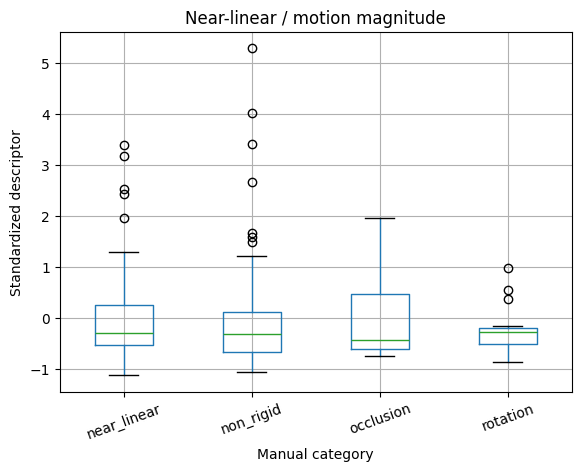

<Figure size 900x500 with 0 Axes>

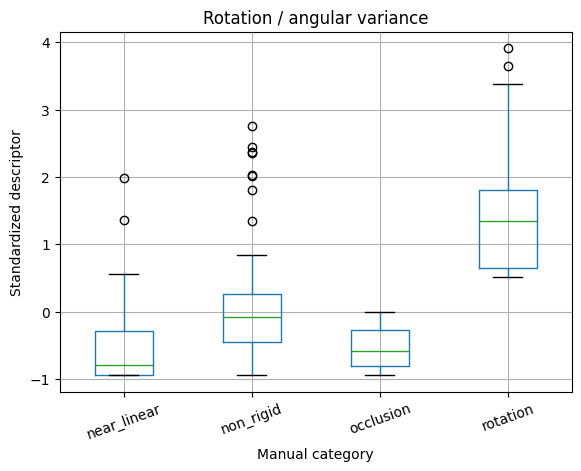

<Figure size 900x500 with 0 Axes>

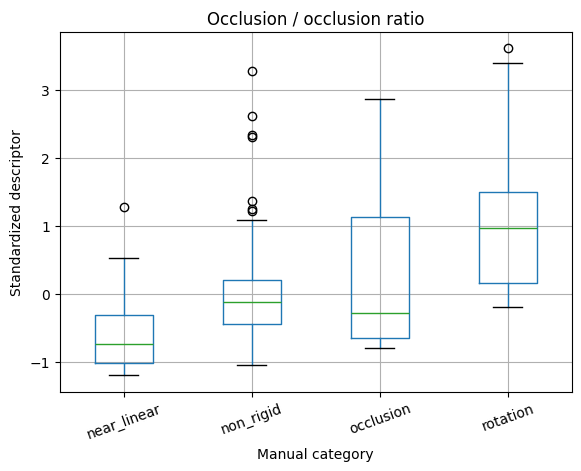

<Figure size 900x500 with 0 Axes>

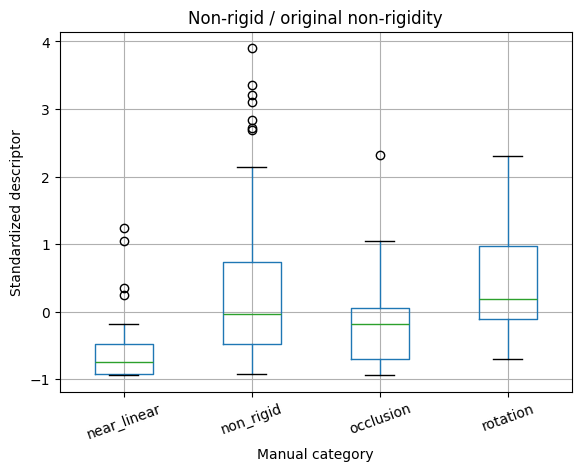

In [36]:
# ============================================================
# BOXPLOTS BY MANUAL CATEGORY
# ============================================================

for descriptor, title in descriptor_info.items():

    z_col = descriptor + "_z"

    plt.figure(figsize=(9, 5))

    cal_z.boxplot(
        column=z_col,
        by="manual_category"
    )

    plt.title(title)
    plt.suptitle("")
    plt.xlabel("Manual category")
    plt.ylabel("Standardized descriptor")
    plt.xticks(rotation=20)

    plt.show()

In [37]:
# ============================================================
# CHECK DESCRIPTOR VALUES BY MANUAL CATEGORY
# ============================================================

descriptor_cols = [
    "magnitude",
    "angular_variance",
    "occlusion_ratio",
    "non_rigidity_original",
    "non_rigidity_improved"
]

for col in descriptor_cols:
    print("\n" + "=" * 70)
    print(col)
    print("=" * 70)

    print(
        cal.groupby("manual_category")[col]
        .agg(["count", "mean", "median", "min", "max"])
        .round(6)
    )


magnitude
                 count      mean    median       min        max
manual_category                                                
near_linear         55  8.543971  6.164531  1.013910  29.171041
non_rigid           70  8.162548  6.098647  1.399749  41.071869
occlusion           21  8.397837  5.388899  3.437169  20.311241
rotation            24  6.329539  6.329866  2.640911  14.183934

angular_variance
                 count      mean    median       min       max
manual_category                                               
near_linear         55  0.004228  0.001599  0.000001  0.029108
non_rigid           70  0.010022  0.008572  0.000028  0.036748
occlusion           21  0.003964  0.003558  0.000007  0.009348
rotation            24  0.024076  0.022683  0.014457  0.048228

occlusion_ratio
                 count      mean    median       min       max
manual_category                                               
near_linear         55  0.051390  0.040531  0.000000  0.215013
non

In [38]:
print(
    cal[cal["manual_category"] == "occlusion"][
        [
            "clip_id",
            "magnitude",
            "angular_variance",
            "occlusion_ratio",
            "mean_fb_error",
            "mean_relative_fb_error",
            "non_rigidity_original",
            "non_rigidity_improved"
        ]
    ].to_string(index=False)
)

   clip_id  magnitude  angular_variance  occlusion_ratio  mean_fb_error  mean_relative_fb_error  non_rigidity_original  non_rigidity_improved
00003/0631  10.385967          0.000011         0.086096       0.545945                0.033787               0.000904               0.008674
00006/0435   8.033789          0.007882         0.236047       2.757903                0.233875               0.205267               0.097183
00007/0897  20.311241          0.000007         0.292992       1.787361                0.044401               0.023573               0.032568
00008/0172   3.962830          0.007203         0.352233       1.755290                0.292701               0.041158               0.054441
00017/0663   4.699028          0.000442         0.068047       0.443096                0.031912               0.101538               0.054553
00019/0445   5.388899          0.006671         0.045554       0.207961                0.414039               0.029855               0.048511
00019/

In [39]:
# ============================================================
# PERCENTILE THRESHOLD SWEEP: 50% → 90%
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

# ------------------------------------------------------------
# Proposal-faithful descriptor mapping
# ------------------------------------------------------------

descriptor_map = {
    "near_linear": "magnitude",
    "rotation": "angular_variance",
    "occlusion": "occlusion_ratio",
    "non_rigid": "non_rigidity_original"
}

descriptor_cols = list(descriptor_map.values())

# ------------------------------------------------------------
# Standardize descriptors using the 170 calibration clips
# ------------------------------------------------------------

scaler = StandardScaler()

cal_z = cal.copy()

z_values = scaler.fit_transform(cal[descriptor_cols])

for i, col in enumerate(descriptor_cols):
    cal_z[col + "_z"] = z_values[:, i]

# ------------------------------------------------------------
# Classification function
# ------------------------------------------------------------

def classify_motion(row, thresholds):

    candidates = {}

    for category, descriptor in descriptor_map.items():

        score = row[descriptor + "_z"]
        threshold = thresholds[category]

        if score >= threshold:
            candidates[category] = score

    # No descriptor exceeds its threshold
    if not candidates:
        return "near_linear"

    # Highest standardized descriptor wins
    return max(candidates, key=candidates.get)


# ------------------------------------------------------------
# Sweep 50% → 90%
# ------------------------------------------------------------

results = []

for percentile in range(50, 91, 5):

    thresholds = {
        category: cal_z[descriptor + "_z"].quantile(percentile / 100)
        for category, descriptor in descriptor_map.items()
    }

    predictions = cal_z.apply(
        lambda row: classify_motion(row, thresholds),
        axis=1
    )

    y_true = cal_z["manual_category"]
    y_pred = predictions

    accuracy = accuracy_score(y_true, y_pred)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[
            "near_linear",
            "rotation",
            "occlusion",
            "non_rigid"
        ],
        zero_division=0
    )

    results.append({
        "percentile": percentile,
        "accuracy": accuracy,
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "macro_f1": f1.mean(),
        "near_linear_f1": f1[0],
        "rotation_f1": f1[1],
        "occlusion_f1": f1[2],
        "non_rigid_f1": f1[3]
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------------------
# Display results
# ------------------------------------------------------------

print("=" * 90)
print("PERCENTILE THRESHOLD SWEEP")
print("=" * 90)

display(
    results_df.style.format({
        "accuracy": "{:.3f}",
        "macro_precision": "{:.3f}",
        "macro_recall": "{:.3f}",
        "macro_f1": "{:.3f}",
        "near_linear_f1": "{:.3f}",
        "rotation_f1": "{:.3f}",
        "occlusion_f1": "{:.3f}",
        "non_rigid_f1": "{:.3f}"
    })
)

# ------------------------------------------------------------
# Best percentile by macro F1
# ------------------------------------------------------------

best_idx = results_df["macro_f1"].idxmax()
best = results_df.loc[best_idx]

print("\n" + "=" * 90)
print("BEST PERCENTILE BY MACRO F1")
print("=" * 90)

print(f"Percentile : {int(best['percentile'])}%")
print(f"Accuracy   : {best['accuracy']:.3f}")
print(f"Macro F1   : {best['macro_f1']:.3f}")

# ------------------------------------------------------------
# Show confusion matrix for every percentile
# ------------------------------------------------------------

labels_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

for percentile in range(50, 91, 5):

    thresholds = {
        category: cal_z[descriptor + "_z"].quantile(percentile / 100)
        for category, descriptor in descriptor_map.items()
    }

    predictions = cal_z.apply(
        lambda row: classify_motion(row, thresholds),
        axis=1
    )

    cm = confusion_matrix(
        cal_z["manual_category"],
        predictions,
        labels=labels_order
    )

    print("\n" + "-" * 90)
    print(f"{percentile}% PERCENTILE")
    print("-" * 90)

    display(
        pd.DataFrame(
            cm,
            index=["True " + x for x in labels_order],
            columns=["Pred " + x for x in labels_order]
        )
    )

PERCENTILE THRESHOLD SWEEP


,percentile,accuracy,macro_precision,macro_recall,macro_f1,near_linear_f1,rotation_f1,occlusion_f1,non_rigid_f1
0,50,0.435,0.443,0.445,0.406,0.596,0.394,0.226,0.408
1,55,0.459,0.454,0.464,0.422,0.650,0.413,0.233,0.392
2,60,0.471,0.459,0.474,0.429,0.667,0.433,0.241,0.375
3,65,0.471,0.459,0.474,0.430,0.646,0.448,0.250,0.375
4,70,0.476,0.475,0.478,0.438,0.623,0.491,0.259,0.379
5,75,0.506,0.516,0.501,0.465,0.649,0.553,0.275,0.383
6,80,0.488,0.504,0.477,0.440,0.629,0.533,0.267,0.330
7,85,0.471,0.504,0.461,0.422,0.607,0.524,0.286,0.273
8,90,0.429,0.487,0.394,0.350,0.573,0.389,0.222,0.217



BEST PERCENTILE BY MACRO F1
Percentile : 75%
Accuracy   : 0.506
Macro F1   : 0.465

------------------------------------------------------------------------------------------
50% PERCENTILE
------------------------------------------------------------------------------------------


,Pred near_linear,Pred rotation,Pred occlusion,Pred non_rigid
True near_linear,34,11,9,1
True rotation,0,13,7,4
True occlusion,9,2,7,3
True non_rigid,16,16,18,20



------------------------------------------------------------------------------------------
55% PERCENTILE
------------------------------------------------------------------------------------------


...

,Pred near_linear,Pred rotation,Pred occlusion,Pred non_rigid
True near_linear,50,3,1,1
True rotation,1,12,7,4
True occlusion,14,0,6,1
True non_rigid,39,6,10,15



------------------------------------------------------------------------------------------
85% PERCENTILE
------------------------------------------------------------------------------------------


,Pred near_linear,Pred rotation,Pred occlusion,Pred non_rigid
True near_linear,51,2,1,1
True rotation,2,11,7,4
True occlusion,14,0,6,1
True non_rigid,46,5,7,12



------------------------------------------------------------------------------------------
90% PERCENTILE
------------------------------------------------------------------------------------------


,Pred near_linear,Pred rotation,Pred occlusion,Pred non_rigid
True near_linear,53,1,1,0
True rotation,9,7,5,3
True occlusion,16,0,4,1
True non_rigid,52,4,5,9


In [40]:
# # ============================================================
# # SHALLOW DECISION TREE — CALIBRATION EXPERIMENT
# # ============================================================

# from sklearn.tree import DecisionTreeClassifier, export_text
# from sklearn.metrics import (
#     accuracy_score,
#     confusion_matrix,
#     classification_report
# )
# import pandas as pd

# # ------------------------------------------------------------
# # Features
# # ------------------------------------------------------------

# features = [
#     "magnitude",
#     "angular_variance",
#     "occlusion_ratio",
#     "mean_fb_error",
#     "mean_relative_fb_error",
#     "non_rigidity_original"
# ]

# X = cal[features]
# y = cal["manual_category"]

# # ------------------------------------------------------------
# # Shallow tree
# # ------------------------------------------------------------

# tree = DecisionTreeClassifier(
#     criterion="gini",
#     max_depth=3,
#     min_samples_leaf=3,
#     random_state=42
# )

# tree.fit(X, y)

# # ------------------------------------------------------------
# # Predictions
# # ------------------------------------------------------------

# pred = tree.predict(X)

# # ------------------------------------------------------------
# # Accuracy
# # ------------------------------------------------------------

# accuracy = accuracy_score(y, pred)

# print("=" * 70)
# print("DECISION TREE CALIBRATION RESULT")
# print("=" * 70)

# print(f"Accuracy: {accuracy:.3f}")
# print(f"Agreement: {accuracy * 100:.1f}%")

# # ------------------------------------------------------------
# # Confusion matrix
# # ------------------------------------------------------------

# labels_order = [
#     "near_linear",
#     "rotation",
#     "occlusion",
#     "non_rigid"
# ]

# cm = confusion_matrix(
#     y,
#     pred,
#     labels=labels_order
# )

# cm_df = pd.DataFrame(
#     cm,
#     index=["Manual: " + x for x in labels_order],
#     columns=["Auto: " + x for x in labels_order]
# )

# print("\n" + "=" * 70)
# print("CONFUSION MATRIX")
# print("=" * 70)

# display(cm_df)

# # ------------------------------------------------------------
# # Classification report
# # ------------------------------------------------------------

# print("\n" + "=" * 70)
# print("CLASSIFICATION REPORT")
# print("=" * 70)

# print(
#     classification_report(
#         y,
#         pred,
#         labels=labels_order,
#         zero_division=0
#     )
# )

# # ------------------------------------------------------------
# # Learned tree rules
# # ------------------------------------------------------------

# print("\n" + "=" * 70)
# print("LEARNED DECISION RULES")
# print("=" * 70)

# print(
#     export_text(
#         tree,
#         feature_names=features,
#         decimals=6
#     )
# )

# # ------------------------------------------------------------
# # Feature importance
# # ------------------------------------------------------------

# print("\n" + "=" * 70)
# print("FEATURE IMPORTANCE")
# print("=" * 70)

# importance_df = pd.DataFrame({
#     "feature": features,
#     "importance": tree.feature_importances_
# }).sort_values(
#     "importance",
#     ascending=False
# )

# display(
#     importance_df.style.format({
#         "importance": "{:.4f}"
#     })
# )

DECISION TREE CALIBRATION RESULT
Accuracy: 0.806
Agreement: 80.6%

CONFUSION MATRIX


,Auto: near_linear,Auto: rotation,Auto: occlusion,Auto: non_rigid
Manual: near_linear,45,3,2,5
Manual: rotation,0,24,0,0
Manual: occlusion,3,0,11,7
Manual: non_rigid,7,4,2,57



CLASSIFICATION REPORT
              precision    recall  f1-score   support

 near_linear       0.82      0.82      0.82        55
    rotation       0.77      1.00      0.87        24
   occlusion       0.73      0.52      0.61        21
   non_rigid       0.83      0.81      0.82        70

    accuracy                           0.81       170
   macro avg       0.79      0.79      0.78       170
weighted avg       0.80      0.81      0.80       170


LEARNED DECISION RULES
|--- mean_fb_error <= 0.457707
|   |--- mean_relative_fb_error <= 0.304762
|   |   |--- mean_fb_error <= 0.440010
|   |   |   |--- class: near_linear
|   |   |--- mean_fb_error >  0.440010
|   |   |   |--- class: near_linear
|   |--- mean_relative_fb_error >  0.304762
|   |   |--- magnitude <= 6.921928
|   |   |   |--- class: near_linear
|   |   |--- magnitude >  6.921928
|   |   |   |--- class: non_rigid
|--- mean_fb_error >  0.457707
|   |--- angular_variance <= 0.013908
|   |   |--- mean_relative_fb_error <= 0

,feature,importance
3,mean_fb_error,0.4185
4,mean_relative_fb_error,0.3106
1,angular_variance,0.2555
0,magnitude,0.0154
2,occlusion_ratio,0.0000
5,non_rigidity_original,0.0000


In [43]:
# ============================================================
# SHALLOW DECISION TREE — CALIBRATION EXPERIMENT
# ============================================================

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import pandas as pd

# ------------------------------------------------------------
# Features
# ------------------------------------------------------------

features = [
    "mean_fb_error",
    "mean_relative_fb_error",
    "angular_variance"
]

X = cal[features]
y = cal["manual_category"]

# ------------------------------------------------------------
# Shallow tree
# ------------------------------------------------------------

tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

tree.fit(X, y)

# ------------------------------------------------------------
# Predictions
# ------------------------------------------------------------

pred = tree.predict(X)

# ------------------------------------------------------------
# Accuracy
# ------------------------------------------------------------

accuracy = accuracy_score(y, pred)

print("=" * 70)
print("DECISION TREE CALIBRATION RESULT")
print("=" * 70)

print(f"Accuracy: {accuracy:.3f}")
print(f"Agreement: {accuracy * 100:.1f}%")

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

labels_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

cm = confusion_matrix(
    y,
    pred,
    labels=labels_order
)

cm_df = pd.DataFrame(
    cm,
    index=["Manual: " + x for x in labels_order],
    columns=["Auto: " + x for x in labels_order]
)

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

display(cm_df)

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y,
        pred,
        labels=labels_order,
        zero_division=0
    )
)

# ------------------------------------------------------------
# Learned tree rules
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("LEARNED DECISION RULES")
print("=" * 70)

print(
    export_text(
        tree,
        feature_names=features,
        decimals=6
    )
)

# ------------------------------------------------------------
# Feature importance
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("FEATURE IMPORTANCE")
print("=" * 70)

importance_df = pd.DataFrame({
    "feature": features,
    "importance": tree.feature_importances_
}).sort_values(
    "importance",
    ascending=False
)

display(
    importance_df.style.format({
        "importance": "{:.4f}"
    })
)

DECISION TREE CALIBRATION RESULT
Accuracy: 0.806
Agreement: 80.6%

CONFUSION MATRIX


,Auto: near_linear,Auto: rotation,Auto: occlusion,Auto: non_rigid
Manual: near_linear,45,3,2,5
Manual: rotation,0,24,0,0
Manual: occlusion,3,0,11,7
Manual: non_rigid,7,4,2,57



CLASSIFICATION REPORT
              precision    recall  f1-score   support

 near_linear       0.82      0.82      0.82        55
    rotation       0.77      1.00      0.87        24
   occlusion       0.73      0.52      0.61        21
   non_rigid       0.83      0.81      0.82        70

    accuracy                           0.81       170
   macro avg       0.79      0.79      0.78       170
weighted avg       0.80      0.81      0.80       170


LEARNED DECISION RULES
|--- mean_fb_error <= 0.457707
|   |--- mean_relative_fb_error <= 0.304762
|   |   |--- mean_fb_error <= 0.440010
|   |   |   |--- class: near_linear
|   |   |--- mean_fb_error >  0.440010
|   |   |   |--- class: near_linear
|   |--- mean_relative_fb_error >  0.304762
|   |   |--- mean_fb_error <= 0.354134
|   |   |   |--- class: near_linear
|   |   |--- mean_fb_error >  0.354134
|   |   |   |--- class: non_rigid
|--- mean_fb_error >  0.457707
|   |--- angular_variance <= 0.013908
|   |   |--- mean_relative_fb_er

,feature,importance
0,mean_fb_error,0.4339
1,mean_relative_fb_error,0.3106
2,angular_variance,0.2555


Validating Testing data

In [44]:
# ============================================================
# SELECT 100 TRAIN CLIPS FOR VISUAL SANITY CHECK
# ============================================================

import os
import pandas as pd

BASE = "/kaggle/input/datasets/hibro00/vfi-csvs"

splits = pd.read_csv(os.path.join(BASE, "splits.csv"))

train_ids = (
    splits[splits["split"] == "train"]["clip_id"]
    .sample(n=100, random_state=42)
    .tolist()
)

train_check = pd.DataFrame({
    "clip_id": train_ids
})

print(f"Selected train clips: {len(train_check)}")
display(train_check.head(20))

Selected train clips: 100


,clip_id
0,00038/0465
1,00061/0263
2,00057/0234
3,00017/0134
4,00013/0221
5,00020/0576
6,00065/0397
7,00076/0980
8,00008/0350
9,00063/0848


In [45]:
train_check.to_csv(
    "train_100_ids.csv",
    index=False
)

print("Saved: train_100_ids.csv")

Saved: train_100_ids.csv


In [46]:
# ============================================================
# LOAD 100 TRAIN CLIPS
# ============================================================

train_100 = pd.read_csv("train_100_ids.csv")

train_ids = train_100["clip_id"].tolist()

print(f"Train clips to process: {len(train_ids)}")
print(train_ids[:10])

Train clips to process: 100
['00038/0465', '00061/0263', '00057/0234', '00017/0134', '00013/0221', '00020/0576', '00065/0397', '00076/0980', '00008/0350', '00063/0848']


In [47]:
# ============================================================
# RAFT DESCRIPTORS — 100 TRAIN CLIPS
# ============================================================

import os
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image

VIMEO_ROOT = "/kaggle/input/datasets/chenshu123/vimeo-triplet/vimeo_triplet"
OUTPUT_PATH = "/kaggle/working/train_100_raft_descriptors.csv"

train_ids = train_100["clip_id"].astype(str).tolist()

results = []

print(f"Starting RAFT extraction for {len(train_ids)} train clips...\n")

for idx, clip_id in enumerate(train_ids, start=1):

    clip_start = time.time()

    try:
        clip_dir = os.path.join(
            VIMEO_ROOT,
            "sequences",
            clip_id
        )

        # Same endpoint frames as calibration/test extraction
        im1 = np.array(
            Image.open(
                f"{clip_dir}/im1.png"
            ).convert("RGB")
        )

        im3 = np.array(
            Image.open(
                f"{clip_dir}/im3.png"
            ).convert("RGB")
        )

        im1 = (
            torch.from_numpy(im1)
            .permute(2, 0, 1)
            .float()
            .unsqueeze(0)
            .to(DEVICE)
        )

        im3 = (
            torch.from_numpy(im3)
            .permute(2, 0, 1)
            .float()
            .unsqueeze(0)
            .to(DEVICE)
        )

        # Same padding
        padder = InputPadder(
            im1.shape,
            mode="sintel"
        )

        im1_p, im3_p = padder.pad(
            im1,
            im3
        )

        # Forward + backward flow
        with torch.no_grad():

            _, flow_fwd = raft_model(
                im1_p,
                im3_p,
                iters=20,
                test_mode=True
            )

            _, flow_bwd = raft_model(
                im3_p,
                im1_p,
                iters=20,
                test_mode=True
            )

        # Remove padding
        flow_fwd = padder.unpad(flow_fwd)
        flow_bwd = padder.unpad(flow_bwd)

        # Same descriptor function
        desc = compute_descriptors(
            flow_fwd,
            flow_bwd,
            kernel_size=KERNEL_SIZE,
            magnitude_threshold=MAGNITUDE_THRESHOLD,
            mag_epsilon=MAG_EPSILON,
            alpha=ALPHA,
            beta=BETA,
            suppress_boundaries=False
        )

        row = {
            "clip_id": clip_id,

            "magnitude":
                desc["primary"]["magnitude"].item(),

            "p90_magnitude":
                desc["secondary"]["p90_magnitude"].item(),

            "active_pixel_ratio":
                desc["secondary"]["active_pixel_ratio"].item(),

            "angular_variance":
                desc["primary"]["angular_variance"].item(),

            "occlusion_ratio":
                desc["primary"]["occlusion_ratio"].item(),

            "mean_fb_error":
                desc["secondary"]["mean_fb_error"].item(),

            "mean_relative_fb_error":
                desc["secondary"]["mean_relative_fb_error"].item(),

            "non_rigidity_original":
                desc["secondary"]["non_rigidity_original"].item(),

            "non_rigidity_improved":
                desc["secondary"]["non_rigidity_improved"].item(),

            "status": "success",

            "time_sec":
                time.time() - clip_start
        }

        results.append(row)

        print(
            f"[{idx:03d}/{len(train_ids)}] "
            f"{clip_id} | "
            f"{row['time_sec']:.2f}s"
        )

    except Exception as e:

        results.append({
            "clip_id": clip_id,
            "magnitude": np.nan,
            "p90_magnitude": np.nan,
            "active_pixel_ratio": np.nan,
            "angular_variance": np.nan,
            "occlusion_ratio": np.nan,
            "mean_fb_error": np.nan,
            "mean_relative_fb_error": np.nan,
            "non_rigidity_original": np.nan,
            "non_rigidity_improved": np.nan,
            "status": f"error: {e}",
            "time_sec": time.time() - clip_start
        })

        print(
            f"[{idx:03d}/{len(train_ids)}] "
            f"{clip_id} | ERROR: {e}"
        )

    # Avoid unnecessary GPU accumulation
    torch.cuda.empty_cache()


train_100_raft = pd.DataFrame(results)

train_100_raft.to_csv(
    OUTPUT_PATH,
    index=False
)

print("\n" + "=" * 60)
print("EXTRACTION COMPLETE")
print("=" * 60)

print("Rows:", len(train_100_raft))
print(
    "Successful:",
    (train_100_raft["status"] == "success").sum()
)
print(
    "Failed:",
    (train_100_raft["status"] != "success").sum()
)

print("\nSaved:")
print(OUTPUT_PATH)

Starting RAFT extraction for 100 train clips...

[001/100] 00038/0465 | 0.35s
[002/100] 00061/0263 | 0.25s
[003/100] 00057/0234 | 0.25s
[004/100] 00017/0134 | 0.25s
[005/100] 00013/0221 | 0.25s
[006/100] 00020/0576 | 0.25s
[007/100] 00065/0397 | 0.26s
[008/100] 00076/0980 | 0.25s
[009/100] 00008/0350 | 0.28s
[010/100] 00063/0848 | 0.25s
[011/100] 00006/0807 | 0.26s
[012/100] 00009/0599 | 0.25s
[013/100] 00053/0493 | 0.26s
[014/100] 00078/0613 | 0.25s
[015/100] 00044/0528 | 0.26s
[016/100] 00025/0146 | 0.24s
[017/100] 00006/0887 | 0.25s
[018/100] 00054/0301 | 0.26s
[019/100] 00018/0399 | 0.26s
[020/100] 00005/0216 | 0.26s
[021/100] 00017/0493 | 0.26s
[022/100] 00005/0923 | 0.26s
[023/100] 00053/0504 | 0.25s
[024/100] 00058/0686 | 0.25s
[025/100] 00011/0991 | 0.26s
[026/100] 00050/0768 | 0.26s
[027/100] 00043/0795 | 0.26s
[028/100] 00012/0965 | 0.25s
[029/100] 00016/0213 | 0.25s
[030/100] 00042/0712 | 0.25s
[031/100] 00002/0191 | 0.26s
[032/100] 00046/0701 | 0.25s
[033/100] 00001/0687 | 

In [49]:
# ============================================================
# APPLY FROZEN CALIBRATION TREE TO 100 TRAIN CLIPS
# ============================================================

from sklearn.tree import DecisionTreeClassifier

features = [
    "mean_fb_error",
    "mean_relative_fb_error",
    "angular_variance"
]

X_cal = cal[features]
y_cal = cal["manual_category"]

# Recreate the exact tree used during calibration
final_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    min_samples_leaf=3,
    random_state=42
)

# Train ONLY on the 50 manually labeled calibration clips
final_tree.fit(X_cal, y_cal)

# Predict the 100 train clips
train_100_raft["predicted_category"] = final_tree.predict(
    train_100_raft[features]
)

# ------------------------------------------------------------
# Category distribution
# ------------------------------------------------------------

print("=" * 70)
print("100 TRAIN CLIPS — PREDICTED CATEGORY DISTRIBUTION")
print("=" * 70)

counts = (
    train_100_raft["predicted_category"]
    .value_counts()
    .reindex([
        "near_linear",
        "rotation",
        "occlusion",
        "non_rigid"
    ])
    .fillna(0)
    .astype(int)
)

display(counts.to_frame("count"))

print("\nPercent:")
display(
    (counts / len(train_100_raft) * 100)
    .round(1)
    .to_frame("percent")
)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------

train_100_raft.to_csv(
    "train_100_classified.csv",
    index=False
)

print("\nSaved: train_100_classified.csv")

100 TRAIN CLIPS — PREDICTED CATEGORY DISTRIBUTION


,count
predicted_category,
near_linear,60
rotation,7
occlusion,9
non_rigid,24



Percent:


,percent
predicted_category,
near_linear,60.0
rotation,7.0
occlusion,9.0
non_rigid,24.0



Saved: train_100_classified.csv


In [50]:
# ============================================================
# SELECT 5 EXAMPLES FROM EACH PREDICTED CATEGORY
# ============================================================

categories = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

examples = []

for category in categories:

    subset = train_100_raft[
        train_100_raft["predicted_category"] == category
    ]

    selected = subset.sample(
        n=min(5, len(subset)),
        random_state=42
    )

    examples.append(selected)

gif_samples = pd.concat(
    examples,
    ignore_index=True
)

print("=" * 70)
print("SELECTED GIF SAMPLES")
print("=" * 70)

display(
    gif_samples[
        [
            "clip_id",
            "predicted_category",
            "mean_fb_error",
            "mean_relative_fb_error",
            "angular_variance"
        ]
    ]
)

SELECTED GIF SAMPLES


,clip_id,predicted_category,mean_fb_error,mean_relative_fb_error,angular_variance
0,00057/0234,near_linear,0.214947,0.019818,6.246456e-04
1,00008/0350,near_linear,0.078251,0.003124,9.828738e-07
2,00010/0650,near_linear,0.373202,0.047345,5.860906e-03
3,00033/0893,near_linear,0.415838,0.130637,6.735107e-03
4,00018/0399,near_linear,0.300519,0.033859,2.933968e-03
5,00006/0807,rotation,0.498556,0.101477,1.502035e-02
6,00042/0712,rotation,0.631443,0.120116,1.461120e-02
7,00074/0645,rotation,0.808553,0.149575,1.460769e-02
8,00002/0191,rotation,0.764523,0.057784,1.634746e-02
9,00042/0842,rotation,1.440122,0.423818,2.158532e-02



PREDICTED: near_linear
00057/0234 | near_linear | FB=0.215 | RelFB=0.020 | Ang=0.00062


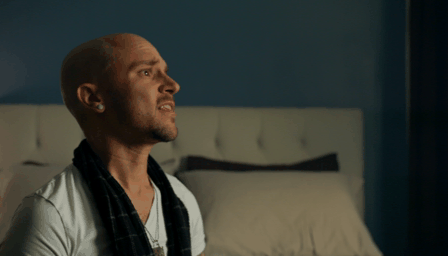

00008/0350 | near_linear | FB=0.078 | RelFB=0.003 | Ang=0.00000


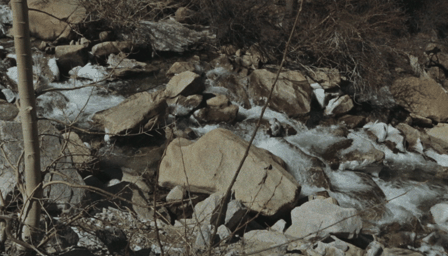

00010/0650 | near_linear | FB=0.373 | RelFB=0.047 | Ang=0.00586


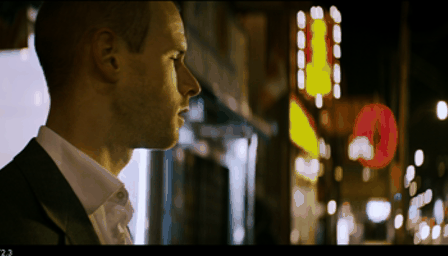

00033/0893 | near_linear | FB=0.416 | RelFB=0.131 | Ang=0.00674


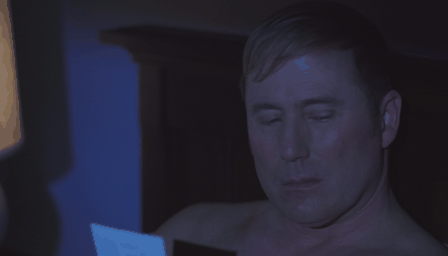

00018/0399 | near_linear | FB=0.301 | RelFB=0.034 | Ang=0.00293


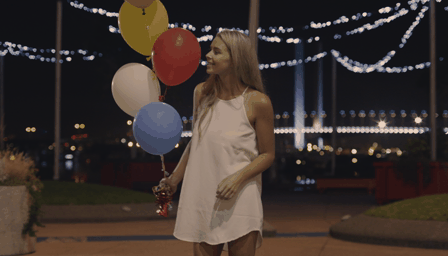


PREDICTED: rotation
00006/0807 | rotation | FB=0.499 | RelFB=0.101 | Ang=0.01502


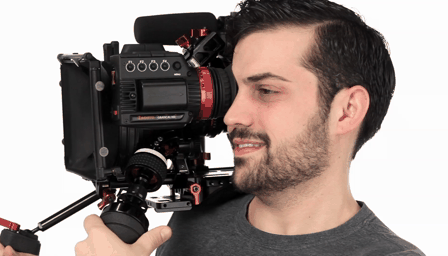

00042/0712 | rotation | FB=0.631 | RelFB=0.120 | Ang=0.01461


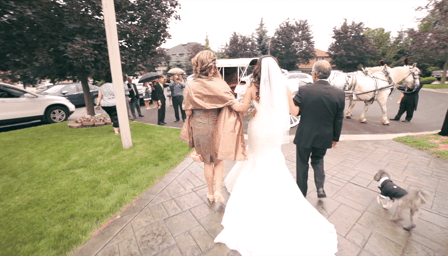

00074/0645 | rotation | FB=0.809 | RelFB=0.150 | Ang=0.01461


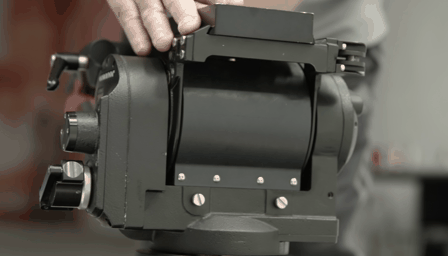

00002/0191 | rotation | FB=0.765 | RelFB=0.058 | Ang=0.01635


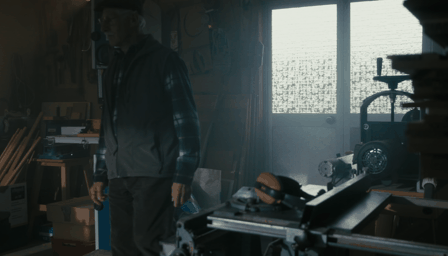

00042/0842 | rotation | FB=1.440 | RelFB=0.424 | Ang=0.02159


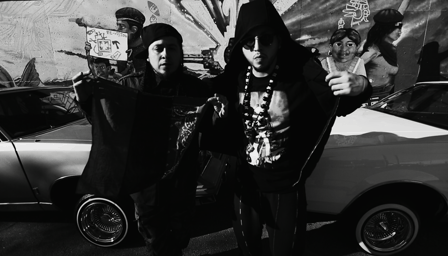


PREDICTED: occlusion
00014/0323 | occlusion | FB=0.554 | RelFB=0.049 | Ang=0.00599


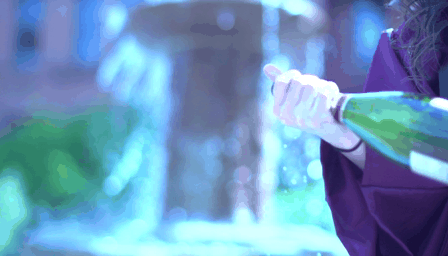

00061/0263 | occlusion | FB=1.717 | RelFB=0.030 | Ang=0.01246


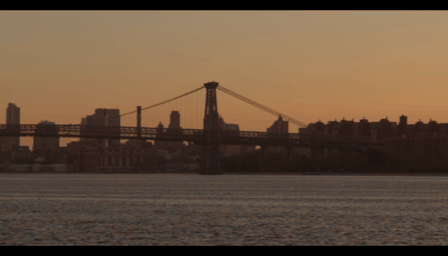

00007/0555 | occlusion | FB=0.668 | RelFB=0.047 | Ang=0.00356


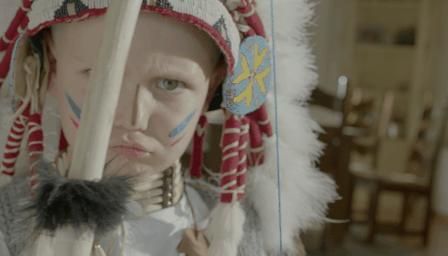

00038/0465 | occlusion | FB=1.138 | RelFB=0.030 | Ang=0.00001


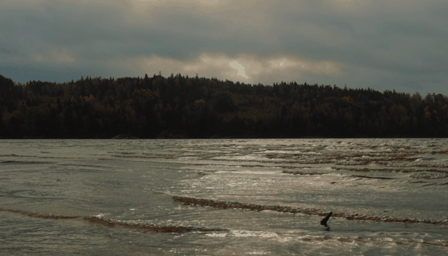

00052/0043 | occlusion | FB=0.468 | RelFB=0.037 | Ang=0.00532


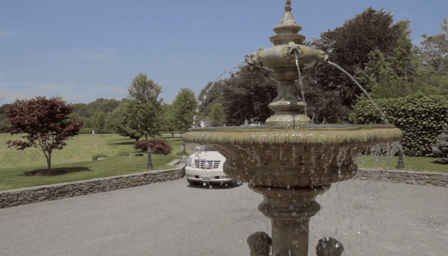


PREDICTED: non_rigid
00014/0538 | non_rigid | FB=0.986 | RelFB=0.098 | Ang=0.01296


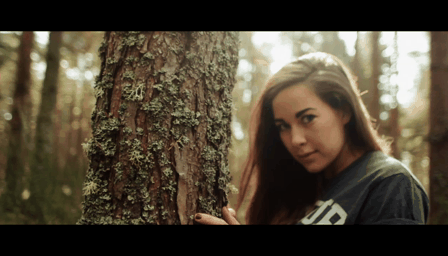

00012/0398 | non_rigid | FB=0.496 | RelFB=0.284 | Ang=0.00865


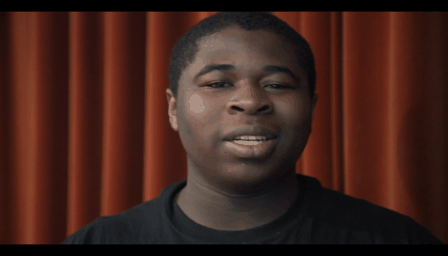

00013/0221 | non_rigid | FB=1.125 | RelFB=0.489 | Ang=0.00696


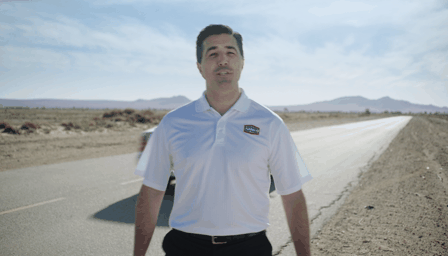

00068/0607 | non_rigid | FB=3.869 | RelFB=0.141 | Ang=0.00020


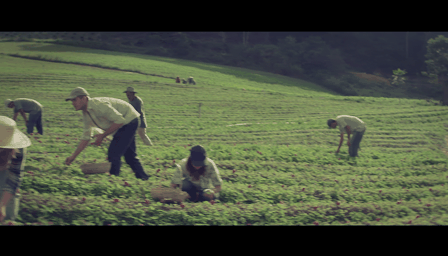

00005/0244 | non_rigid | FB=0.742 | RelFB=0.066 | Ang=0.00014


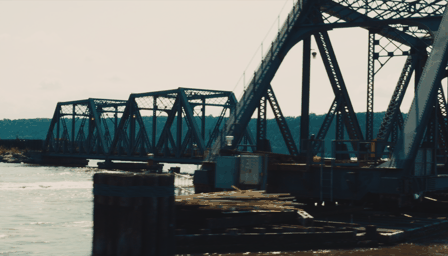

In [51]:
# ============================================================
# GENERATE GIFS FOR VISUAL INSPECTION
# ============================================================

import os
import imageio.v2 as imageio
from IPython.display import display, Image

GIF_DIR = "/kaggle/working/train_100_gifs"
os.makedirs(GIF_DIR, exist_ok=True)

for category in categories:

    print("\n" + "=" * 70)
    print(f"PREDICTED: {category}")
    print("=" * 70)

    subset = gif_samples[
        gif_samples["predicted_category"] == category
    ]

    for _, row in subset.iterrows():

        clip_id = row["clip_id"]

        clip_dir = os.path.join(
            VIMEO_ROOT,
            "sequences",
            clip_id
        )

        frames = []

        for name in ["im1.png", "im2.png", "im3.png"]:

            path = os.path.join(
                clip_dir,
                name
            )

            if os.path.exists(path):
                frames.append(
                    imageio.imread(path)
                )

        if len(frames) != 3:
            print(f"Missing frames: {clip_id}")
            continue

        gif_path = os.path.join(
            GIF_DIR,
            f"{category}_{clip_id.replace('/', '_')}.gif"
        )

        imageio.mimsave(
            gif_path,
            frames,
            duration=0.35,
            loop=0
        )

        print(
            f"{clip_id} | "
            f"{category} | "
            f"FB={row['mean_fb_error']:.3f} | "
            f"RelFB={row['mean_relative_fb_error']:.3f} | "
            f"Ang={row['angular_variance']:.5f}"
        )

        display(Image(filename=gif_path))

In [52]:
rotation_all = train_100_raft[
    train_100_raft["predicted_category"] == "rotation"
].copy()

display(
    rotation_all[
        [
            "clip_id",
            "mean_fb_error",
            "mean_relative_fb_error",
            "angular_variance"
        ]
    ].sort_values("angular_variance", ascending=False)
)

,clip_id,mean_fb_error,mean_relative_fb_error,angular_variance
51,00042/0842,1.440122,0.423818,0.021585
33,00045/0311,1.179815,0.095139,0.021184
88,00006/0803,0.586383,0.077140,0.020137
30,00002/0191,0.764523,0.057784,0.016347
10,00006/0807,0.498556,0.101477,0.015020
29,00042/0712,0.631443,0.120116,0.014611
70,00074/0645,0.808553,0.149575,0.014608


00006/0807 | Ang=0.015020 | FB=0.499 | RelFB=0.101


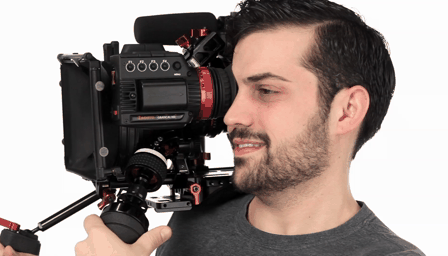

00042/0712 | Ang=0.014611 | FB=0.631 | RelFB=0.120


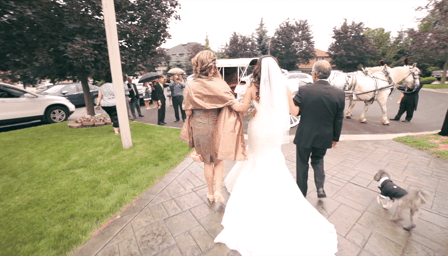

00002/0191 | Ang=0.016347 | FB=0.765 | RelFB=0.058


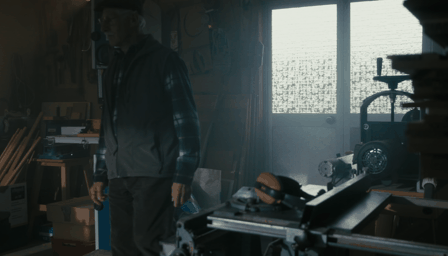

00045/0311 | Ang=0.021184 | FB=1.180 | RelFB=0.095


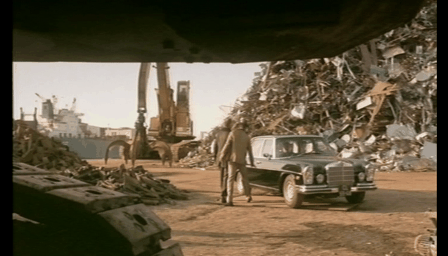

00042/0842 | Ang=0.021585 | FB=1.440 | RelFB=0.424


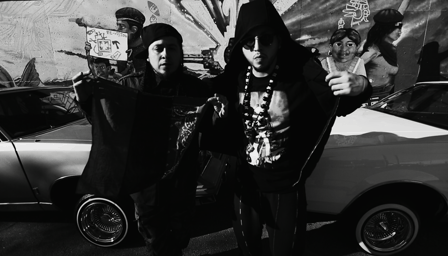

00074/0645 | Ang=0.014608 | FB=0.809 | RelFB=0.150


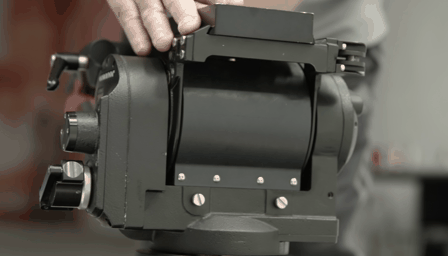

00006/0803 | Ang=0.020137 | FB=0.586 | RelFB=0.077


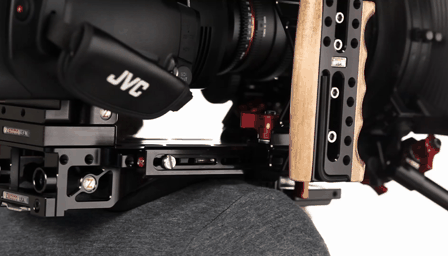

In [53]:
# ============================================================
# SHOW ALL PREDICTED ROTATION CLIPS
# ============================================================

rotation_gif_dir = "/kaggle/working/rotation_check"
os.makedirs(rotation_gif_dir, exist_ok=True)

for _, row in rotation_all.iterrows():

    clip_id = row["clip_id"]

    clip_dir = os.path.join(
        VIMEO_ROOT,
        "sequences",
        clip_id
    )

    frames = []

    for name in ["im1.png", "im2.png", "im3.png"]:
        path = os.path.join(clip_dir, name)

        if os.path.exists(path):
            frames.append(imageio.imread(path))

    if len(frames) != 3:
        print("Missing:", clip_id)
        continue

    gif_path = os.path.join(
        rotation_gif_dir,
        f"{clip_id.replace('/', '_')}.gif"
    )

    imageio.mimsave(
        gif_path,
        frames,
        duration=0.35,
        loop=0
    )

    print(
        f"{clip_id} | "
        f"Ang={row['angular_variance']:.6f} | "
        f"FB={row['mean_fb_error']:.3f} | "
        f"RelFB={row['mean_relative_fb_error']:.3f}"
    )

    display(Image(filename=gif_path))

In [54]:
# ============================================================
# SVM CLASSIFIER SWEEP
# 4-FOLD STRATIFIED CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score
)

# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

features = [
    "magnitude",
    "angular_variance",
    "occlusion_ratio",
    "mean_fb_error",
    "mean_relative_fb_error",
    "non_rigidity_original",
    "non_rigidity_improved"
]

X = cal[features].copy()
y = cal["manual_category"].copy()

labels_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

# ------------------------------------------------------------
# CROSS-VALIDATION
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# SVM CONFIGURATIONS
# ------------------------------------------------------------

models = {

    "Linear SVM C=0.1": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="linear",
            C=0.1,
            class_weight="balanced"
        ))
    ]),

    "Linear SVM C=1": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="linear",
            C=1,
            class_weight="balanced"
        ))
    ]),

    "Linear SVM C=10": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="linear",
            C=10,
            class_weight="balanced"
        ))
    ]),

    "RBF SVM C=0.1": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=0.1,
            gamma="scale",
            class_weight="balanced"
        ))
    ]),

    "RBF SVM C=1": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=1,
            gamma="scale",
            class_weight="balanced"
        ))
    ]),

    "RBF SVM C=10": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced"
        ))
    ]),

    "RBF SVM C=100": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=100,
            gamma="scale",
            class_weight="balanced"
        ))
    ])
}

# ------------------------------------------------------------
# RUN CV
# ------------------------------------------------------------

results = []

for name, model in models.items():

    accuracy_scores = []
    macro_f1_scores = []
    macro_precision_scores = []
    macro_recall_scores = []

    for train_idx, val_idx in cv.split(X, y):

        X_train = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]

        model.fit(X_train, y_train)

        pred = model.predict(X_val)

        accuracy_scores.append(
            accuracy_score(y_val, pred)
        )

        macro_f1_scores.append(
            f1_score(
                y_val,
                pred,
                labels=labels_order,
                average="macro",
                zero_division=0
            )
        )

        macro_precision_scores.append(
            precision_score(
                y_val,
                pred,
                labels=labels_order,
                average="macro",
                zero_division=0
            )
        )

        macro_recall_scores.append(
            recall_score(
                y_val,
                pred,
                labels=labels_order,
                average="macro",
                zero_division=0
            )
        )

    results.append({
        "model": name,
        "accuracy_mean": np.mean(accuracy_scores),
        "accuracy_std": np.std(accuracy_scores),
        "macro_f1_mean": np.mean(macro_f1_scores),
        "macro_f1_std": np.std(macro_f1_scores),
        "macro_precision": np.mean(macro_precision_scores),
        "macro_recall": np.mean(macro_recall_scores)
    })

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

svm_results = pd.DataFrame(results)

svm_results = svm_results.sort_values(
    "macro_f1_mean",
    ascending=False
).reset_index(drop=True)

print("=" * 100)
print("SVM CROSS-VALIDATION RESULTS")
print("=" * 100)

display(
    svm_results.style.format({
        "accuracy_mean": "{:.3f}",
        "accuracy_std": "{:.3f}",
        "macro_f1_mean": "{:.3f}",
        "macro_f1_std": "{:.3f}",
        "macro_precision": "{:.3f}",
        "macro_recall": "{:.3f}"
    })
)

# ------------------------------------------------------------
# BEST MODEL
# ------------------------------------------------------------

best_svm = svm_results.iloc[0]

print("\n" + "=" * 100)
print("BEST SVM")
print("=" * 100)

print(f"Model          : {best_svm['model']}")
print(f"Accuracy       : {best_svm['accuracy_mean']:.3f} +/- {best_svm['accuracy_std']:.3f}")
print(f"Macro F1       : {best_svm['macro_f1_mean']:.3f} +/- {best_svm['macro_f1_std']:.3f}")
print(f"Macro Precision: {best_svm['macro_precision']:.3f}")
print(f"Macro Recall   : {best_svm['macro_recall']:.3f}")

SVM CROSS-VALIDATION RESULTS


,model,accuracy_mean,accuracy_std,macro_f1_mean,macro_f1_std,macro_precision,macro_recall
0,RBF SVM C=10,0.623,0.066,0.600,0.070,0.636,0.600
1,RBF SVM C=100,0.617,0.101,0.588,0.105,0.645,0.582
2,RBF SVM C=1,0.594,0.028,0.564,0.035,0.557,0.591
3,Linear SVM C=0.1,0.588,0.080,0.535,0.079,0.534,0.569
4,Linear SVM C=1,0.583,0.069,0.531,0.056,0.547,0.569
5,Linear SVM C=10,0.553,0.067,0.502,0.056,0.514,0.540
6,RBF SVM C=0.1,0.505,0.071,0.446,0.067,0.495,0.517



BEST SVM
Model          : RBF SVM C=10
Accuracy       : 0.623 +/- 0.066
Macro F1       : 0.600 +/- 0.070
Macro Precision: 0.636
Macro Recall   : 0.600


In [55]:
# ============================================================
# FINAL CLASSIFIER COMPARISON
# Percentile baseline vs Decision Tree
# Stratified cross-validation
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer, f1_score

# ------------------------------------------------------------
# Features / labels
# ------------------------------------------------------------

features = [
    "magnitude",
    "angular_variance",
    "occlusion_ratio",
    "mean_fb_error",
    "mean_relative_fb_error",
    "non_rigidity_original"
]

X = cal[features]
y = cal["manual_category"]

labels_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

# ------------------------------------------------------------
# Stratified CV
# ------------------------------------------------------------

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# ============================================================
# DECISION TREE
# ============================================================

tree_scores = []

for train_idx, val_idx in cv.split(X, y):

    X_train = X.iloc[train_idx]
    X_val = X.iloc[val_idx]

    y_train = y.iloc[train_idx]
    y_val = y.iloc[val_idx]

    tree = DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        min_samples_leaf=3,
        random_state=42
    )

    tree.fit(X_train, y_train)

    pred = tree.predict(X_val)

    tree_scores.append(
        f1_score(
            y_val,
            pred,
            labels=labels_order,
            average="macro",
            zero_division=0
        )
    )

# ============================================================
# PERCENTILE CLASSIFIER
# ============================================================

descriptor_map = {
    "near_linear": "magnitude",
    "rotation": "angular_variance",
    "occlusion": "occlusion_ratio",
    "non_rigid": "non_rigidity_original"
}

percentiles = range(50, 91, 5)

percentile_results = []

for percentile in percentiles:

    fold_scores = []

    for train_idx, val_idx in cv.split(X, y):

        cal_train = cal.iloc[train_idx]
        cal_val = cal.iloc[val_idx]

        # Standardize using TRAIN fold only
        from sklearn.preprocessing import StandardScaler

        scaler_cv = StandardScaler()

        desc_cols = list(descriptor_map.values())

        train_z = scaler_cv.fit_transform(
            cal_train[desc_cols]
        )

        val_z = scaler_cv.transform(
            cal_val[desc_cols]
        )

        train_z = pd.DataFrame(
            train_z,
            columns=desc_cols,
            index=cal_train.index
        )

        val_z = pd.DataFrame(
            val_z,
            columns=desc_cols,
            index=cal_val.index
        )

        thresholds = {
            category:
            train_z[descriptor].quantile(
                percentile / 100
            )
            for category, descriptor
            in descriptor_map.items()
        }

        predictions = []

        for idx in cal_val.index:

            candidates = {}

            for category, descriptor in descriptor_map.items():

                score = val_z.loc[idx, descriptor]

                if score >= thresholds[category]:
                    candidates[category] = score

            if not candidates:
                prediction = "near_linear"
            else:
                prediction = max(
                    candidates,
                    key=candidates.get
                )

            predictions.append(prediction)

        score = f1_score(
            cal_val["manual_category"],
            predictions,
            labels=labels_order,
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    percentile_results.append({
        "percentile": percentile,
        "macro_f1": np.mean(fold_scores),
        "std": np.std(fold_scores)
    })

# ============================================================
# RESULTS
# ============================================================

percentile_df = pd.DataFrame(percentile_results)

print("=" * 75)
print("CROSS-VALIDATED CLASSIFIER COMPARISON")
print("=" * 75)

print("\nDecision Tree:")
print(
    f"Macro F1 = {np.mean(tree_scores):.3f} "
    f"+/- {np.std(tree_scores):.3f}"
)

print("\nPercentile methods:")
display(
    percentile_df.style.format({
        "macro_f1": "{:.3f}",
        "std": "{:.3f}"
    })
)

best_percentile_row = percentile_df.loc[
    percentile_df["macro_f1"].idxmax()
]

print("\n" + "=" * 75)
print("COMPARISON")
print("=" * 75)

print(
    f"Best percentile: "
    f"{int(best_percentile_row['percentile'])}% "
    f"(Macro F1 = {best_percentile_row['macro_f1']:.3f})"
)

print(
    f"Decision Tree: "
    f"Macro F1 = {np.mean(tree_scores):.3f}"
)

CROSS-VALIDATED CLASSIFIER COMPARISON

Decision Tree:
Macro F1 = 0.718 +/- 0.050

Percentile methods:


,percentile,macro_f1,std
0,50,0.388,0.056
1,55,0.396,0.047
2,60,0.412,0.056
3,65,0.412,0.058
4,70,0.416,0.057
5,75,0.437,0.067
6,80,0.414,0.039
7,85,0.385,0.074
8,90,0.341,0.109



COMPARISON
Best percentile: 75% (Macro F1 = 0.437)
Decision Tree: Macro F1 = 0.718


In [56]:
# ============================================================
# FIX + ANALYZE EXISTING K-MEANS RESULTS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    confusion_matrix
)
from scipy.optimize import linear_sum_assignment

# ------------------------------------------------------------
# REBUILD CALIBRATION DATA WITH LABELS
# ------------------------------------------------------------

cal_labeled = raft_cal.merge(
    labels,
    on="clip_id",
    how="inner"
).copy()

# ------------------------------------------------------------
# GET CLUSTER ASSIGNMENTS FROM EXISTING K-MEANS
# ------------------------------------------------------------

# all_descriptors already contains the K-Means assignments
cal_results = all_descriptors[
    all_descriptors["source"] == "calibration"
].copy()

# Add manual labels by clip_id
cal_results = cal_results.merge(
    cal_labeled[
        ["clip_id", "manual_category"]
    ],
    on="clip_id",
    how="inner"
)

print("=" * 80)
print("CALIBRATION CLUSTER ANALYSIS")
print("=" * 80)

print(f"Calibration clips with labels: {len(cal_results)}")

# ------------------------------------------------------------
# RAW CLUSTER / CATEGORY TABLE
# ------------------------------------------------------------

cross_tab = pd.crosstab(
    cal_results["manual_category"],
    cal_results["cluster"]
)

print("\n" + "=" * 80)
print("MANUAL CATEGORY vs K-MEANS CLUSTER")
print("=" * 80)

display(cross_tab)

# ------------------------------------------------------------
# ARI / NMI
# ------------------------------------------------------------

y_true = cal_results["manual_category"]
y_cluster = cal_results["cluster"]

ari = adjusted_rand_score(
    y_true,
    y_cluster
)

nmi = normalized_mutual_info_score(
    y_true,
    y_cluster
)

print(f"\nAdjusted Rand Index (ARI): {ari:.3f}")
print(f"Normalized Mutual Information (NMI): {nmi:.3f}")

# ------------------------------------------------------------
# BEST ONE-TO-ONE CLUSTER → CATEGORY MAPPING
# ------------------------------------------------------------

category_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

cluster_order = sorted(
    cal_results["cluster"].unique()
)

cm = confusion_matrix(
    y_true,
    y_cluster,
    labels=category_order
)

# Hungarian algorithm
row_ind, col_ind = linear_sum_assignment(-cm)

mapping = {}

for r, c in zip(row_ind, col_ind):

    if c < len(cluster_order):
        mapping[cluster_order[c]] = category_order[r]

print("\n" + "=" * 80)
print("CLUSTER → CATEGORY MAPPING")
print("=" * 80)

for cluster in sorted(mapping):
    print(
        f"Cluster {cluster} → {mapping[cluster]}"
    )

# ------------------------------------------------------------
# APPLY MAPPING
# ------------------------------------------------------------

cal_results["mapped_category"] = (
    cal_results["cluster"]
    .map(mapping)
)

mapped_accuracy = (
    cal_results["mapped_category"]
    == cal_results["manual_category"]
).mean()

print(
    f"\nMapped calibration agreement: "
    f"{mapped_accuracy:.3f}"
)

# ------------------------------------------------------------
# MAPPED CONFUSION MATRIX
# ------------------------------------------------------------

mapped_cm = pd.crosstab(
    cal_results["manual_category"],
    cal_results["mapped_category"]
)

print("\n" + "=" * 80)
print("MAPPED CONFUSION MATRIX")
print("=" * 80)

display(
    mapped_cm.reindex(
        index=category_order,
        columns=category_order,
        fill_value=0
    )
)

# ------------------------------------------------------------
# SHOW WHICH CALIBRATION CLIPS FALL INTO EACH CLUSTER
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CALIBRATION CLIPS BY CLUSTER")
print("=" * 80)

for cluster in sorted(cal_results["cluster"].unique()):

    subset = cal_results[
        cal_results["cluster"] == cluster
    ]

    print(
        f"\nCluster {cluster} "
        f"({len(subset)} clips) "
        f"→ {mapping.get(cluster, 'unmapped')}"
    )

    display(
        subset[
            [
                "clip_id",
                "manual_category",
                "cluster"
            ]
        ].sort_values("manual_category")
    )

NameError: name 'all_descriptors' is not defined

In [12]:
# ===========================================================================
# AUTHORITATIVE FINAL CALIBRATION SEARCH (170-CLIP CALIBRATION SPLIT)
# This self-contained search is the source of the final feature/classifier
# decision. It supersedes the earlier historical calibration experiments above.
# Run this cell before the Final Classifier cell below.
# ===========================================================================
# ============================================================
# AUTOMATIC DESCRIPTOR + CLASSIFIER SEARCH
# SELF-CONTAINED VERSION
# ALL 127 FEATURE COMBINATIONS
# ============================================================

import os
import itertools
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score

# ============================================================
# LOAD CALIBRATION DATA
# ============================================================

BASE = "/kaggle/input/datasets/hibro00/vfi-csvs"

raft_cal = pd.read_csv(
    os.path.join(
        BASE,
        "vimeo_170_motion_descriptors.csv"
    )
)

labels = pd.read_csv(
    os.path.join(
        BASE,
        "calibration_manual_labels.csv"
    )
)

cal = raft_cal.merge(
    labels,
    on="clip_id",
    how="inner"
)

print("=" * 100)
print("CALIBRATION DATA")
print("=" * 100)

print(f"Descriptor clips : {len(raft_cal)}")
print(f"Label clips      : {len(labels)}")
print(f"Matched clips    : {len(cal)}")

# ============================================================
# DESCRIPTORS
# ============================================================

all_features = [
    "magnitude",
    "angular_variance",
    "occlusion_ratio",
    "mean_fb_error",
    "mean_relative_fb_error",
    "non_rigidity_original",
    "non_rigidity_improved"
]

X_all = cal[all_features].copy()
y = cal["manual_category"].copy()

labels_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

# ============================================================
# CROSS-VALIDATION
# ============================================================

cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=42
)

# ============================================================
# CLASSIFIERS
# ============================================================

model_configs = {

    "RBF_SVM_C1": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="rbf",
            C=1,
            gamma="scale",
            class_weight="balanced"
        ))
    ]),

    "Linear_SVM_C1": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            kernel="linear",
            C=1,
            class_weight="balanced"
        ))
    ]),

    "Decision_Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=3,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42
    )
}

# ============================================================
# ALL FEATURE COMBINATIONS
# ============================================================

feature_combinations = []

for r in range(1, len(all_features) + 1):

    for combo in itertools.combinations(
        all_features,
        r
    ):
        feature_combinations.append(combo)

print("\n" + "=" * 100)
print("SEARCH SETUP")
print("=" * 100)

print(f"Descriptors available : {len(all_features)}")
print(f"Feature combinations  : {len(feature_combinations)}")
print(f"Classifiers           : {len(model_configs)}")
print(
    f"Total experiments     : "
    f"{len(feature_combinations) * len(model_configs)}"
)

# ============================================================
# SEARCH
# ============================================================

results = []

for combo_number, features in enumerate(
    feature_combinations,
    start=1
):

    X = X_all[list(features)]

    for model_name, model in model_configs.items():

        fold_f1 = []
        fold_accuracy = []

        for train_idx, val_idx in cv.split(X, y):

            X_train = X.iloc[train_idx]
            X_val = X.iloc[val_idx]

            y_train = y.iloc[train_idx]
            y_val = y.iloc[val_idx]

            model.fit(
                X_train,
                y_train
            )

            pred = model.predict(X_val)

            fold_f1.append(
                f1_score(
                    y_val,
                    pred,
                    labels=labels_order,
                    average="macro",
                    zero_division=0
                )
            )

            fold_accuracy.append(
                accuracy_score(
                    y_val,
                    pred
                )
            )

        results.append({

            "features": " + ".join(features),

            "n_features": len(features),

            "model": model_name,

            "macro_f1": np.mean(fold_f1),

            "macro_f1_std": np.std(fold_f1),

            "accuracy": np.mean(fold_accuracy),

            "accuracy_std": np.std(fold_accuracy)

        })

    if combo_number % 10 == 0:

        print(
            f"Completed "
            f"{combo_number}/"
            f"{len(feature_combinations)}"
        )

# ============================================================
# RESULTS
# ============================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    [
        "macro_f1",
        "accuracy"
    ],
    ascending=False
).reset_index(drop=True)

# ============================================================
# TOP 20
# ============================================================

print("\n" + "=" * 100)
print("TOP 20 CONFIGURATIONS — MACRO F1")
print("=" * 100)

display(
    results_df.head(20).style.format({
        "macro_f1": "{:.3f}",
        "macro_f1_std": "{:.3f}",
        "accuracy": "{:.3f}",
        "accuracy_std": "{:.3f}"
    })
)

# ============================================================
# BEST
# ============================================================

best = results_df.iloc[0]

print("\n" + "=" * 100)
print("BEST CONFIGURATION")
print("=" * 100)

print(f"Features        : {best['features']}")
print(f"Number features : {int(best['n_features'])}")
print(f"Classifier      : {best['model']}")
print(
    f"Macro F1        : "
    f"{best['macro_f1']:.3f} "
    f"+/- {best['macro_f1_std']:.3f}"
)
print(
    f"Accuracy        : "
    f"{best['accuracy']:.3f} "
    f"+/- {best['accuracy_std']:.3f}"
)

# ============================================================
# BEST PER CLASSIFIER
# ============================================================

print("\n" + "=" * 100)
print("BEST CONFIGURATION PER CLASSIFIER")
print("=" * 100)

best_by_model = (
    results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .groupby(
        "model",
        as_index=False
    )
    .first()
)

display(
    best_by_model[
        [
            "model",
            "features",
            "n_features",
            "macro_f1",
            "macro_f1_std",
            "accuracy",
            "accuracy_std"
        ]
    ].style.format({
        "macro_f1": "{:.3f}",
        "macro_f1_std": "{:.3f}",
        "accuracy": "{:.3f}",
        "accuracy_std": "{:.3f}"
    })
)

# ============================================================
# FEATURE FREQUENCY IN TOP 20
# ============================================================

print("\n" + "=" * 100)
print("FEATURE FREQUENCY IN TOP 20")
print("=" * 100)

top20 = results_df.head(20)

feature_frequency = {
    feature: 0
    for feature in all_features
}

for feature_string in top20["features"]:

    selected = feature_string.split(" + ")

    for feature in selected:

        feature_frequency[feature] += 1

feature_frequency_df = (
    pd.DataFrame(
        list(feature_frequency.items()),
        columns=[
            "feature",
            "top20_count"
        ]
    )
    .sort_values(
        "top20_count",
        ascending=False
    )
)

display(feature_frequency_df)

# ============================================================
# SAVE
# ============================================================

results_df.to_csv(
    "automatic_descriptor_classifier_search.csv",
    index=False
)

print(
    "\nSaved: "
    "automatic_descriptor_classifier_search.csv"
)

CALIBRATION DATA
Descriptor clips : 170
Label clips      : 170
Matched clips    : 170

SEARCH SETUP
Descriptors available : 7
Feature combinations  : 127
Classifiers           : 3
Total experiments     : 381
Completed 10/127
Completed 20/127
Completed 30/127
Completed 40/127
Completed 50/127
Completed 60/127
Completed 70/127
Completed 80/127
Completed 90/127
Completed 100/127
Completed 110/127
Completed 120/127

TOP 20 CONFIGURATIONS — MACRO F1


,features,n_features,model,macro_f1,macro_f1_std,accuracy,accuracy_std
0,angular_variance + mean_fb_error + mean_relative_fb_error,3,Decision_Tree,0.728,0.049,0.753,0.033
1,magnitude + angular_variance + mean_fb_error + mean_relative_fb_error,4,Decision_Tree,0.728,0.049,0.753,0.033
2,angular_variance + occlusion_ratio + mean_fb_error + mean_relative_fb_error,4,Decision_Tree,0.728,0.049,0.753,0.033
3,angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_original,4,Decision_Tree,0.728,0.049,0.753,0.033
4,angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_improved,4,Decision_Tree,0.728,0.049,0.753,0.033
5,magnitude + angular_variance + occlusion_ratio + mean_fb_error + mean_relative_fb_error,5,Decision_Tree,0.728,0.049,0.753,0.033
6,magnitude + angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_original,5,Decision_Tree,0.728,0.049,0.753,0.033
7,magnitude + angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_improved,5,Decision_Tree,0.728,0.049,0.753,0.033
8,angular_variance + occlusion_ratio + mean_fb_error + mean_relative_fb_error + non_rigidity_original,5,Decision_Tree,0.728,0.049,0.753,0.033
9,angular_variance + occlusion_ratio + mean_fb_error + mean_relative_fb_error + non_rigidity_improved,5,Decision_Tree,0.728,0.049,0.753,0.033



BEST CONFIGURATION
Features        : angular_variance + mean_fb_error + mean_relative_fb_error
Number features : 3
Classifier      : Decision_Tree
Macro F1        : 0.728 +/- 0.049
Accuracy        : 0.753 +/- 0.033

BEST CONFIGURATION PER CLASSIFIER


,model,features,n_features,macro_f1,macro_f1_std,accuracy,accuracy_std
0,Decision_Tree,angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_original,4,0.728,0.049,0.753,0.033
1,Linear_SVM_C1,angular_variance + mean_fb_error + non_rigidity_original,3,0.612,0.088,0.617,0.077
2,RBF_SVM_C1,magnitude + angular_variance + mean_fb_error + mean_relative_fb_error + non_rigidity_improved,5,0.659,0.037,0.676,0.027



FEATURE FREQUENCY IN TOP 20


,feature,top20_count
1,angular_variance,20
4,mean_relative_fb_error,20
3,mean_fb_error,18
0,magnitude,12
2,occlusion_ratio,11
6,non_rigidity_improved,11
5,non_rigidity_original,9



Saved: automatic_descriptor_classifier_search.csv


# ***Final Classifier***

In [16]:
# ===========================================================================
# FINAL CLASSIFIER USED FOR THE REPORTED LABELS
# This classifier follows the final 170-clip calibration search above. The next
# cells apply it first to training descriptors and then to the untouched test
# descriptors; do not substitute results from the historical cells above.
# ===========================================================================
# ============================================================
# FINAL CLASSIFIER
# Decision Tree trained on 170 manually labelled calibration clips
# ============================================================

from sklearn.tree import DecisionTreeClassifier

# Final feature set selected during calibration
final_features = [
    "angular_variance",
    "mean_fb_error",
    "mean_relative_fb_error"
]

# Calibration data
X_cal_final = cal[final_features]
y_cal_final = cal["manual_category"]

# Final Decision Tree
final_classifier = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

final_classifier.fit(X_cal_final, y_cal_final)

print("FINAL CLASSIFIER")
print("Model: Decision Tree")
print("Training clips:", len(X_cal_final))
print("Features:", final_features)
print("Classes:", final_classifier.classes_)

FINAL CLASSIFIER
Model: Decision Tree
Training clips: 170
Features: ['angular_variance', 'mean_fb_error', 'mean_relative_fb_error']
Classes: ['near_linear' 'non_rigid' 'occlusion' 'rotation']


In [17]:
# ============================================================
# CLASSIFY TRAINING CLIPS
# Apply final Decision Tree to RAFT training descriptors
# ============================================================

TRAIN_DESC_PATH = "/kaggle/working/catalog/raft_descriptors_train.csv"
CLASSIFIED_OUTPUT = "/kaggle/working/catalog/raft_descriptors_train_classified.csv"

train_desc = pd.read_csv(TRAIN_DESC_PATH)

# Only classify successfully processed clips
valid_mask = train_desc["status"] == "success"

train_desc["predicted_category"] = None

train_desc.loc[valid_mask, "predicted_category"] = final_classifier.predict(
    train_desc.loc[valid_mask, final_features]
)

train_desc.to_csv(CLASSIFIED_OUTPUT, index=False)

print("CLASSIFICATION COMPLETE")
print("Total clips:", len(train_desc))
print("Successfully classified:", valid_mask.sum())
print()
print(train_desc.loc[valid_mask, "predicted_category"].value_counts())
print()
print("Saved to:")
print(CLASSIFIED_OUTPUT)

CLASSIFICATION COMPLETE
Total clips: 51324
Successfully classified: 51324

predicted_category
near_linear    27315
non_rigid      16272
occlusion       4757
rotation        2980
Name: count, dtype: int64

Saved to:
/kaggle/working/catalog/raft_descriptors_train_classified.csv


In [18]:
# ============================================================
# VERIFY CLASSIFIED TRAIN CSV
# ============================================================

classified = pd.read_csv(CLASSIFIED_OUTPUT)

print("Shape:", classified.shape)
print()
print(classified["predicted_category"].value_counts(dropna=False))
print()
print(classified.head())

Shape: (51324, 13)

predicted_category
near_linear    27315
non_rigid      16272
occlusion       4757
rotation        2980
Name: count, dtype: int64

      clip_id  magnitude  p90_magnitude  active_pixel_ratio  angular_variance  \
0  00001/0001   5.660494       8.639277            1.000000          0.000405   
1  00001/0002   5.544868       8.811387            0.999303          0.000287   
2  00001/0003   5.375505       7.902840            1.000000          0.001118   
3  00001/0004   4.845757       8.559772            0.996120          0.003797   
4  00001/0005   3.930233       7.407440            0.991786          0.002987   

   occlusion_ratio  mean_fb_error  mean_relative_fb_error  \
0         0.120460       0.488522                0.039807   
1         0.121229       0.486001                0.042741   
2         0.114293       0.434118                0.039014   
3         0.057389       0.371288                0.043297   
4         0.068152       0.296547                0.047927 

In [14]:
# ===========================================================================
# FINAL TEST-SET LABELLING
# Uses the frozen final classifier selected on the separate 170-clip calibration
# split. The 3,601 test clips are not used to select the classifier.
# ===========================================================================
# ============================================================
# PREDICT MOTION CATEGORIES FOR THE UNTOUCHED TEST SET
# ============================================================

# Load RAFT descriptors for all clips
raft_all = pd.read_csv(
    os.path.join(BASE, "raft_descriptors.csv")
)

# Keep only the descriptor columns needed by the final classifier
descriptor_cols = [
    "clip_id",
    "angular_variance",
    "mean_fb_error",
    "mean_relative_fb_error"
]

# Merge descriptors into the test split
test = test.merge(
    raft_all[descriptor_cols],
    on="clip_id",
    how="left"
)

# Check that all test clips received descriptors
missing = test[final_features].isna().any(axis=1).sum()

print("TEST SET")
print("Test clips:", len(test))
print("Missing descriptor rows:", missing)

# Predict categories
X_test_final = test[final_features]

test["predicted_category"] = final_classifier.predict(X_test_final)

print("\nPREDICTED CATEGORY DISTRIBUTION")
print(test["predicted_category"].value_counts())

TEST SET
Test clips: 3601
Missing descriptor rows: 0

PREDICTED CATEGORY DISTRIBUTION
predicted_category
near_linear    1928
non_rigid      1171
occlusion       322
rotation        180
Name: count, dtype: int64


In [15]:
# ============================================================
# SAVE FINAL TEST MOTION CLASSIFICATIONS
# ============================================================

classification_cols = [
    "clip_id",
    "angular_variance",
    "mean_fb_error",
    "mean_relative_fb_error",
    "predicted_category"
]

test_classification = test[classification_cols].copy()

output_path = "/kaggle/working/test_motion_classifications.csv"
test_classification.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Rows:", len(test_classification))
print("\nCategory distribution:")
print(test_classification["predicted_category"].value_counts())

Saved: /kaggle/working/test_motion_classifications.csv
Rows: 3601

Category distribution:
predicted_category
near_linear    1928
non_rigid      1171
occlusion       322
rotation        180
Name: count, dtype: int64


# ***MOTION-CATEGORY-AWARE VFI DIAGNOSTIC BENCHMARKING***

In [65]:
# ===========================================================================
# FINAL DIAGNOSTIC ANALYSIS
# Consumes the final saved test classifications and frozen-model metrics.
# ===========================================================================
# ============================================================
# MOTION-CATEGORY-AWARE VFI DIAGNOSTIC BENCHMARKING
# ============================================================

import os
import pandas as pd
import numpy as np

BASE = "/kaggle/input/datasets/hibro00/vfi-csvs"

# ------------------------------------------------------------
# 1. LOAD TEST MOTION CLASSIFICATIONS
# ------------------------------------------------------------

classification_path = os.path.join(
    BASE,
    "test_motion_classifications.csv"
)

test_classes = pd.read_csv(classification_path)

print("TEST CLASSIFICATIONS")
print("Rows:", len(test_classes))
print("Columns:", test_classes.columns.tolist())

print("\nCategory distribution:")
print(test_classes["predicted_category"].value_counts())


# ------------------------------------------------------------
# 2. LOAD VFI METRICS
# ------------------------------------------------------------

rife = pd.read_csv(
    os.path.join(BASE, "rife_metrics.csv")
)

film = pd.read_csv(
    os.path.join(BASE, "film_metrics.csv")
)

ifrnet = pd.read_csv(
    os.path.join(BASE, "ifrnet_metrics.csv")
)

print("\nVFI METRICS")
print("RIFE:", rife.shape)
print("FILM:", film.shape)
print("IFRNet:", ifrnet.shape)


# ------------------------------------------------------------
# 3. KEEP ONLY THE CURRENT TEST SET
# ------------------------------------------------------------

# The metric files were generated using the old 3,732-clip
# test split. Our final test split contains 3,601 clips.
# Therefore, use the classification file as the authoritative
# list of clips belonging to the final untouched test set.

test_ids = test_classes[["clip_id"]].drop_duplicates()

print("\nFINAL TEST SET")
print("Unique test clips:", len(test_ids))

assert len(test_ids) == 3601, \
    f"Expected 3601 test clips, found {len(test_ids)}"


# ------------------------------------------------------------
# 4. MERGE MOTION CATEGORIES WITH EACH MODEL
# ------------------------------------------------------------

rife_test = test_classes.merge(
    rife,
    on="clip_id",
    how="inner"
)

film_test = test_classes.merge(
    film,
    on="clip_id",
    how="inner"
)

ifrnet_test = test_classes.merge(
    ifrnet,
    on="clip_id",
    how="inner"
)


# ------------------------------------------------------------
# 5. VERIFY MATCHING
# ------------------------------------------------------------

print("\nMATCHED TEST CLIPS")
print("RIFE:", len(rife_test))
print("FILM:", len(film_test))
print("IFRNet:", len(ifrnet_test))

assert len(rife_test) == 3601
assert len(film_test) == 3601
assert len(ifrnet_test) == 3601

assert rife_test["clip_id"].is_unique
assert film_test["clip_id"].is_unique
assert ifrnet_test["clip_id"].is_unique


# ------------------------------------------------------------
# 6. ADD MODEL IDENTIFIER
# ------------------------------------------------------------

rife_test["model"] = "RIFE"
film_test["model"] = "FILM"
ifrnet_test["model"] = "IFRNet"


# ------------------------------------------------------------
# 7. COMBINE ALL THREE MODELS
# ------------------------------------------------------------

diagnostic_df = pd.concat(
    [
        rife_test,
        film_test,
        ifrnet_test
    ],
    ignore_index=True
)

print("\nCOMBINED DIAGNOSTIC DATASET")
print("Rows:", len(diagnostic_df))
print("Columns:", diagnostic_df.columns.tolist())

print("\nRows per model:")
print(diagnostic_df["model"].value_counts())

print("\nRows per category:")
print(diagnostic_df["predicted_category"].value_counts())


# ------------------------------------------------------------
# 8. CHECK FOR MISSING METRICS
# ------------------------------------------------------------

metric_cols = [
    "psnr",
    "ssim",
    "lpips"
]

print("\nMISSING METRICS")

for col in metric_cols:
    print(
        f"{col}:",
        diagnostic_df[col].isna().sum()
    )

assert diagnostic_df[metric_cols].notna().all().all(), \
    "Missing metric values detected."


# ------------------------------------------------------------
# 9. SAVE COMBINED DIAGNOSTIC DATASET
# ------------------------------------------------------------

diagnostic_output = (
    "/kaggle/working/"
    "vfi_motion_category_diagnostic_results.csv"
)

diagnostic_df.to_csv(
    diagnostic_output,
    index=False
)

print("\nSaved:")
print(diagnostic_output)

TEST CLASSIFICATIONS
Rows: 3601
Columns: ['clip_id', 'angular_variance', 'mean_fb_error', 'mean_relative_fb_error', 'predicted_category']

Category distribution:
predicted_category
near_linear    1928
non_rigid      1171
occlusion       322
rotation        180
Name: count, dtype: int64

VFI METRICS
RIFE: (3732, 6)
FILM: (3732, 6)
IFRNet: (3732, 6)

FINAL TEST SET
Unique test clips: 3601

MATCHED TEST CLIPS
RIFE: 3601
FILM: 3601
IFRNet: 3601

COMBINED DIAGNOSTIC DATASET
Rows: 10803
Columns: ['clip_id', 'angular_variance', 'mean_fb_error', 'mean_relative_fb_error', 'predicted_category', 'psnr', 'ssim', 'lpips', 'inference_time_sec', 'status', 'model']

Rows per model:
model
RIFE      3601
FILM      3601
IFRNet    3601
Name: count, dtype: int64

Rows per category:
predicted_category
near_linear    5784
non_rigid      3513
occlusion       966
rotation        540
Name: count, dtype: int64

MISSING METRICS
psnr: 0
ssim: 0
lpips: 0

Saved:
/kaggle/working/vfi_motion_category_diagnostic_result

In [67]:
# ============================================================
# CATEGORY-WISE VFI PERFORMANCE
# ============================================================

category_order = [
    "near_linear",
    "rotation",
    "occlusion",
    "non_rigid"
]

category_metrics = (
    diagnostic_df
    .groupby(
        ["model", "predicted_category"],
        observed=True
    )[["psnr", "ssim", "lpips"]]
    .agg(
        ["mean", "std", "count"]
    )
    .reset_index()
)

print(category_metrics.to_string(index=False))

 model predicted_category      psnr                    ssim                   lpips               
                               mean      std count     mean      std count     mean      std count
  FILM        near_linear 36.938345 4.631487  1928 0.972478 0.019140  1928 0.018376 0.015786  1928
  FILM          non_rigid 35.220515 4.590378  1171 0.968164 0.020875  1171 0.021368 0.015990  1171
  FILM          occlusion 35.336630 4.884023   322 0.967169 0.021686   322 0.022732 0.016604   322
  FILM           rotation 33.336939 4.069951   180 0.961842 0.021610   180 0.025038 0.016537   180
IFRNet        near_linear 36.749227 4.571790  1928 0.971249 0.019473  1928 0.017902 0.014021  1928
IFRNet          non_rigid 34.900728 4.571199  1171 0.966322 0.021566  1171 0.021730 0.014914  1171
IFRNet          occlusion 35.007154 4.842410   322 0.965142 0.022360   322 0.022874 0.015709   322
IFRNet           rotation 32.989862 3.974708   180 0.959542 0.022282   180 0.026671 0.017064   180
  RIFE    

In [69]:
# ============================================================
# DIAGNOSTIC SCORE (Eq. 1-3) — WEAKEST CATEGORY PER MODEL
# ============================================================

category_order = ["near_linear", "rotation", "occlusion", "non_rigid"]
weights = {"psnr": 0.5, "ssim": 0.25, "lpips": 0.25}

# Per-model, per-category mean metrics
agg = (
    diagnostic_df
    .groupby(["model", "predicted_category"], observed=True)[["psnr", "ssim", "lpips"]]
    .mean()
    .reset_index()
)

diagnostic_rows = []

for model_name, group in agg.groupby("model"):
    group = group.set_index("predicted_category").reindex(category_order)

    norm = pd.DataFrame(index=group.index)

    # PSNR, SSIM: higher is better -> standard min-max
    for metric in ["psnr", "ssim"]:
        lo, hi = group[metric].min(), group[metric].max()
        norm[metric] = (group[metric] - lo) / (hi - lo)

    # LPIPS: lower is better -> min-max then invert
    lo, hi = group["lpips"].min(), group["lpips"].max()
    norm["lpips"] = 1 - ((group["lpips"] - lo) / (hi - lo))

    # Weighted diagnostic score D_c
    norm["D_c"] = (
        weights["psnr"] * norm["psnr"]
        + weights["ssim"] * norm["ssim"]
        + weights["lpips"] * norm["lpips"]
    )

    weakest_category = norm["D_c"].idxmin()

    for category in category_order:
        diagnostic_rows.append({
            "model": model_name,
            "category": category,
            "psnr_norm": norm.loc[category, "psnr"],
            "ssim_norm": norm.loc[category, "ssim"],
            "lpips_norm": norm.loc[category, "lpips"],
            "D_c": norm.loc[category, "D_c"],
            "is_weakest": category == weakest_category
        })

diagnostic_score_df = pd.DataFrame(diagnostic_rows)

print("========== DIAGNOSTIC SCORES (Eq. 1-3) ==========\n")
print(diagnostic_score_df.to_string(index=False))

print("\n========== WEAKEST CATEGORY PER MODEL ==========\n")
weakest_summary = (
    diagnostic_score_df[diagnostic_score_df["is_weakest"]]
    [["model", "category", "D_c"]]
    .rename(columns={"category": "weakest_category"})
)
print(weakest_summary.to_string(index=False))

output_path = "/kaggle/working/diagnostic_scores.csv"
diagnostic_score_df.to_csv(output_path, index=False)
print(f"\nSaved: {output_path}")

========== DIAGNOSTIC SCORES (Eq. 1-3) ==========

 model    category  psnr_norm  ssim_norm  lpips_norm      D_c  is_weakest
  FILM near_linear   1.000000   1.000000    1.000000 1.000000       False
  FILM    rotation   0.000000   0.000000    0.000000 0.000000        True
  FILM   occlusion   0.555253   0.500899    0.346078 0.489371       False
  FILM   non_rigid   0.523011   0.594424    0.550844 0.547823       False
IFRNet near_linear   1.000000   1.000000    1.000000 1.000000       False
IFRNet    rotation   0.000000   0.000000    0.000000 0.000000        True
IFRNet   occlusion   0.536604   0.478383    0.432928 0.496130       False
IFRNet   non_rigid   0.508295   0.579179    0.563394 0.539791       False
  RIFE near_linear   1.000000   1.000000    1.000000 1.000000       False
  RIFE    rotation   0.000000   0.000000    0.000000 0.000000        True
  RIFE   occlusion   0.549052   0.444348    0.401967 0.486105       False
  RIFE   non_rigid   0.502459   0.569327    0.555168 0.532353

In [70]:
# ============================================================
# SECOND-WEAKEST CATEGORY PER MODEL
# ============================================================

diagnostic_score_df["rank"] = (
    diagnostic_score_df
    .groupby("model")["D_c"]
    .rank(method="first", ascending=True)
)

second_weakest_summary = (
    diagnostic_score_df[diagnostic_score_df["rank"] == 2]
    [["model", "category", "D_c"]]
    .rename(columns={"category": "second_weakest_category"})
)

print("========== 2ND WEAKEST CATEGORY PER MODEL ==========\n")
print(second_weakest_summary.to_string(index=False))

print("\n========== FULL RANKING (1=weakest ... 4=strongest) ==========\n")
ranking_view = (
    diagnostic_score_df
    .sort_values(["model", "rank"])
    [["model", "rank", "category", "D_c"]]
)
print(ranking_view.to_string(index=False))

diagnostic_score_df.to_csv("/kaggle/working/diagnostic_scores.csv", index=False)

========== 2ND WEAKEST CATEGORY PER MODEL ==========

 model second_weakest_category      D_c
  FILM               occlusion 0.489371
IFRNet               occlusion 0.496130
  RIFE               occlusion 0.486105

========== FULL RANKING (1=weakest ... 4=strongest) ==========

 model  rank    category      D_c
  FILM   1.0    rotation 0.000000
  FILM   2.0   occlusion 0.489371
  FILM   3.0   non_rigid 0.547823
  FILM   4.0 near_linear 1.000000
IFRNet   1.0    rotation 0.000000
IFRNet   2.0   occlusion 0.496130
IFRNet   3.0   non_rigid 0.539791
IFRNet   4.0 near_linear 1.000000
  RIFE   1.0    rotation 0.000000
  RIFE   2.0   occlusion 0.486105
  RIFE   3.0   non_rigid 0.532353
  RIFE   4.0 near_linear 1.000000


In [71]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix

y_pred_cv = cross_val_predict(final_classifier, X_cal_final, y_cal_final, cv=4)

print(classification_report(y_cal_final, y_pred_cv))
print(pd.DataFrame(
    confusion_matrix(y_cal_final, y_pred_cv, labels=category_order),
    index=[f"true_{c}" for c in category_order],
    columns=[f"pred_{c}" for c in category_order]
))

              precision    recall  f1-score   support

 near_linear       0.71      0.75      0.73        55
   non_rigid       0.71      0.70      0.71        70
   occlusion       0.40      0.29      0.33        21
    rotation       0.75      0.88      0.81        24

    accuracy                           0.69       170
   macro avg       0.64      0.65      0.64       170
weighted avg       0.68      0.69      0.68       170

                  pred_near_linear  pred_rotation  pred_occlusion  \
true_near_linear                41              3               4   
true_rotation                    0             21               0   
true_occlusion                   5              0               6   
true_non_rigid                  12              4               5   

                  pred_non_rigid  
true_near_linear               7  
true_rotation                  3  
true_occlusion                10  
true_non_rigid                49  
